# Лабораторная работа №2
# Выполнил студент группы МОАм-251 Козырев А.Д.

Сравниваю pandas, Dask и Spark на одной задаче, агрегации кликстрима интернет-магазина: время, память, ввод-вывод и загрузку CPU на разных объёмах данных. Затем разбираю физический план Spark, ищу skew, измеряю эффект оптимизаций, сравниваю pandas с Polars и DuckDB и выбираю инструмент для рекомендательной системы из ЛР-1.

In [1]:
import importlib.util, subprocess, sys, os, re
_need = {'pyspark': 'pyspark', 'dask': 'dask[dataframe]', 'polars': 'polars', 'duckdb': 'duckdb',
         'pyarrow': 'pyarrow', 'great_expectations': 'great_expectations', 'psutil': 'psutil',
         'kagglehub': 'kagglehub', 'jdk': 'install-jdk'}
_missing = [pkg for mod, pkg in _need.items() if importlib.util.find_spec(mod) is None]
if _missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], check=True)

import glob, json, math, shutil, statistics, threading, time, urllib.request, logging, warnings, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import pyspark
import dask, polars, duckdb, pyarrow
import great_expectations as gx
from pyspark import SparkContext
from pyspark.sql import SparkSession, functions as F
from IPython.display import display

warnings.filterwarnings('ignore')
logging.getLogger('great_expectations').setLevel(logging.ERROR)
os.environ['GX_ANALYTICS_ENABLED'] = 'False'

SEED = 42
N_CORES = os.cpu_count()
RAM_GB = psutil.virtual_memory().total / 2**30

CSV = '2019-Oct.csv'
WORK = 'work'
CLEAN_PQ = f'{WORK}/clean_parquet'
CLEAN_CSV = f'{WORK}/clean_csv'
OUT = f'{WORK}/out'
for _d in (WORK, OUT, f'{WORK}/spark_tmp'):
    os.makedirs(_d, exist_ok=True)

# pyspark 4.x требует Java 17+, pyspark 3.5 работает и с Java 8/11
def java_major(java_bin):
    try:
        out = subprocess.run([java_bin, '-version'], capture_output=True, text=True).stderr
    except OSError:
        return 0
    m = re.search(r'version "(\d+)(?:\.(\d+))?', out)
    if not m:
        return 0
    major = int(m.group(1))
    return int(m.group(2)) if major == 1 else major

NEED_JAVA = 17 if int(pyspark.__version__.split('.')[0]) >= 4 else 8
_java = (os.path.join(os.environ['JAVA_HOME'], 'bin', 'java') if os.environ.get('JAVA_HOME')
         else shutil.which('java'))
if not _java or java_major(_java) < NEED_JAVA:
    _local = sorted(glob.glob(os.path.expanduser('~/.jdk/jdk-17*')))
    if not _local:
        import jdk
        _local = [jdk.install('17', jre=True, path=os.path.expanduser('~/.jdk'))]
    os.environ['JAVA_HOME'] = _local[-1]
    _java = os.path.join(_local[-1], 'bin', 'java')
os.environ['PATH'] = os.path.dirname(_java) + os.pathsep + os.environ['PATH']
os.environ['PYSPARK_PYTHON'] = sys.executable

def gpu_info():
    if not shutil.which('nvidia-smi'):
        return None
    r = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total,driver_version', '--format=csv,noheader'],
                       capture_output=True, text=True)
    return r.stdout.strip() or None

GPU = gpu_info()

# Тарифы Yandex Compute Cloud (регион Россия, с НДС), как в ЛР-1
PRICE = {'vm_vcpu_hour': 1.24, 'vm_ram_gb_hour': 0.33}

COLORS = {'pandas': '#2a78d6', 'dask': '#eb6834', 'spark': '#1baf7a', 'polars': '#4a3aa7', 'duckdb': '#eda100',
          'cudf': '#e34948'}
plt.rcParams.update({
    'figure.figsize': (10, 4.2), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#b5b4ad',
    'axes.grid': True, 'grid.color': '#e6e5df', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'lines.linewidth': 2, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e', 'legend.frameon': False,
})
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 200)

## Выбор датасета и задачи обработки

Вариант 5, как в ЛР-1: **E-commerce Clickstream**, файл `2019-Oct.csv` из набора *eCommerce behavior data from multi category store* (Kaggle, mkechinov). Это все события мультикатегорийного магазина за октябрь 2019 года (просмотры, корзины, покупки): 42,4 млн строк, 5,3 ГБ.

In [2]:
if not os.path.exists(CSV):
    import kagglehub
    kagglehub.dataset_download('mkechinov/ecommerce-behavior-data-from-multi-category-store',
                               path='2019-Oct.csv', output_dir='.')
    shutil.rmtree('.complete', ignore_errors=True)

print(f'{CSV}: {os.path.getsize(CSV):,} байт'.replace(',', ' '))
with open(CSV) as f:
    for _ in range(3):
        print(f.readline().rstrip())

100%|██████████| 1.61G/1.61G [01:38<00:00, 17.6MB/s]


Extracting zip of 2019-Oct.csv...
2019-Oct.csv: 5 668 612 855 байт
event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
2019-10-01 00:00:00 UTC,view,44600062,2103807459595387724,,shiseido,35.79,541312140,72d76fde-8bb3-4e00-8c23-a032dfed738c
2019-10-01 00:00:00 UTC,view,3900821,2053013552326770905,appliances.environment.water_heater,aqua,33.20,554748717,9333dfbd-b87a-4708-9857-6336556b0fcc


Задача обработки: **1. Агрегация с группировкой**. Для каждой пары «бренд, тип события» (`brand`, `event_type`) считаются число событий, число уникальных пользователей, выручка (сумма `price`) и средняя цена. Это воронка по брендам: сколько людей смотрят бренд, кладут в корзину и покупают. Для рекомендательной системы из ЛР-1 это базовый признак популярности и конверсии бренда.

Почему эта задача, а не остальные:
- в данных нет текста и геоданных, поэтому задача 4 (неструктурированные данные) неприменима;
- для соединения (задача 2) нет второй таблицы, справочник пришлось бы строить из тех же событий;
- в агрегации есть уникальные пользователи (`COUNT DISTINCT`), а это тяжёлая операция с шаффлом. При этом ключ сильно неравномерный: у 14% событий бренд не указан, а несколько брендов (samsung, apple, xiaomi) дают большую часть событий. Значит, на этой задаче есть что анализировать в плане выполнения и в skew.

## Часть 1: Подготовка окружения и данных

### 1) Установите необходимые библиотеки:

Библиотеки ставятся в первом блоке кода, только если их нет в окружении. Spark требует Java: pyspark 4.x работает только с Java 17+, поэтому при отсутствии подходящей Java блок сам скачивает JRE 17 в домашний каталог (пакет `install-jdk`). Ниже версии и железо, на которых получены все замеры: время и память зависят от числа ядер и объёма RAM, поэтому сравнивать числа имеет смысл только внутри одного запуска.

In [3]:
env = pd.DataFrame([
    ('CPU, логических ядер', N_CORES),
    ('RAM, ГБ', round(RAM_GB, 1)),
    ('GPU', GPU or 'нет'),
    ('Python', sys.version.split()[0]),
    ('pandas', pd.__version__), ('Dask', dask.__version__), ('PySpark', pyspark.__version__),
    ('Polars', polars.__version__), ('DuckDB', duckdb.__version__), ('PyArrow', pyarrow.__version__),
    ('Great Expectations', gx.__version__),
    ('Java', f'{java_major(_java)} ({os.environ.get("JAVA_HOME") or _java})'),
], columns=['Компонент', 'Значение'])
display(env)

,Компонент,Значение
0,"CPU, логических ядер",2
1,"RAM, ГБ",12.7
2,GPU,нет
3,Python,3.13.16
4,pandas,2.2.3
5,Dask,2026.8.0
6,PySpark,4.0.4
7,Polars,1.35.2
8,DuckDB,1.3.2
9,PyArrow,23.0.1


### 2) Загрузите датасет и выполните первичную очистку:

Очистку делаю в Spark: полный файл в pandas не помещается в память (это проверяется в Части 2), а Spark читает CSV потоком и удаляет дубликаты через шаффл с выгрузкой на диск. Конфигурация сессии описана в пункте 4.

Правила очистки (их обоснование дано в ЛР-1, Часть 4):
- **дубликаты:** полные дубли строк удаляются (`dropDuplicates`), это повторно записанные события;
- **пропуски:** `brand` и `category_code` заполняются значением `unknown`. Удалять такие строки нельзя: это 14% и 32% событий, к тому же пропуски неслучайные (у дешёвых товаров кода категории нет чаще). Строки без `user_session` (их единицы) удаляются, сессию не восстановить;
- **аномалии:** события с ценой `<= 0` удаляются, у них нет смысла для выручки и средней цены.

Очищенные данные сохраняются дважды: в Parquet (для Части 5 и трека A Части 6) и в CSV (основной вход для сравнения в Части 2). Spark пишет каждый формат в 200 файлов. Строки распределены по файлам хешем от всех полей, поэтому каждый файл является случайной выборкой событий за весь месяц.

Блок дважды читает весь CSV (статистика и очистка) и делает шаффл всех 42 млн строк. Готовые файлы при повторном запуске не пересчитываются.

In [4]:
SPARK_CONF = {
    'spark.sql.shuffle.partitions': '200',
    'spark.default.parallelism': '200',
    'spark.driver.memory': f'{int(RAM_GB * 0.4 * 1024)}m',
    'spark.local.dir': os.path.abspath(f'{WORK}/spark_tmp'),
    'spark.ui.showConsoleProgress': 'false',
}
SCHEMA = ('event_time STRING, event_type STRING, product_id BIGINT, category_id BIGINT, '
          'category_code STRING, brand STRING, price DOUBLE, user_id BIGINT, user_session STRING')
KEY = ['brand', 'event_type']


def start_spark():
    b = SparkSession.builder.master('local[*]').appName('BigDataLab2')
    for k, v in SPARK_CONF.items():
        b = b.config(k, v)
    s = b.getOrCreate()
    s.sparkContext.setLogLevel('ERROR')
    return s


def stop_spark(s):
    # останавливаем и саму JVM, иначе её память не освободится для замеров
    s.stop()
    gw = SparkContext._gateway
    if gw is not None:
        gw.shutdown()
        gw.proc.stdin.close()
        gw.proc.wait(60)
        SparkContext._gateway = None
        SparkContext._jvm = None


spark = start_spark()
raw = spark.read.csv(CSV, header=True, schema=SCHEMA)
STATS_JSON = f'{WORK}/clean_stats.json'

if os.path.exists(STATS_JSON) and os.path.exists(f'{CLEAN_CSV}/_SUCCESS'):
    with open(STATS_JSON) as fh:
        clean_stats = json.load(fh)
    print('Очищенные данные уже есть, пересчёт пропущен')
else:
    t0 = time.perf_counter()
    clean_stats = raw.agg(
        F.count('*').alias('rows'),
        *[F.sum(F.col(c).isNull().cast('int')).alias(f'null_{c}') for c in raw.columns],
        F.sum((F.col('price') <= 0).cast('int')).alias('price_le0'),
        F.sum(((F.col('price') > 0) & F.col('user_session').isNotNull()).cast('int')).alias('valid'),
    ).first().asDict()
    clean = (raw.filter((F.col('price') > 0) & F.col('user_session').isNotNull())
                .dropDuplicates()
                .fillna({'brand': 'unknown', 'category_code': 'unknown'}))
    clean.write.mode('overwrite').parquet(CLEAN_PQ)
    spark.read.parquet(CLEAN_PQ).write.mode('overwrite').option('header', True).csv(CLEAN_CSV)
    clean_stats['clean_rows'] = spark.read.parquet(CLEAN_PQ).count()
    clean_stats['seconds'] = time.perf_counter() - t0
    with open(STATS_JSON, 'w') as fh:
        json.dump(clean_stats, fh)

cs = clean_stats
steps = pd.DataFrame([
    ('Строк в исходном файле', cs['rows'], ''),
    ('Цена <= 0 или пусто', cs['price_le0'] + cs['null_price'], 'удалены'),
    ('Пустой user_session', cs['null_user_session'], 'удалены'),
    ('Полные дубликаты (после фильтров)', cs['valid'] - cs['clean_rows'], 'удалены'),
    ('Пустой brand', cs['null_brand'], 'заполнено unknown'),
    ('Пустой category_code', cs['null_category_code'], 'заполнено unknown'),
    ('Строк после очистки', cs['clean_rows'], ''),
], columns=['Показатель', 'Строк', 'Действие'])
steps['Доля исходных, %'] = (steps['Строк'] / cs['rows'] * 100).round(3)
display(steps)
print(f'Очистка заняла {cs["seconds"]:.0f} с')

,Показатель,Строк,Действие,"Доля исходных, %"
0,Строк в исходном файле,42448764,,100.000
1,Цена <= 0 или пусто,68673,удалены,0.162
2,Пустой user_session,2,удалены,0.000
3,Полные дубликаты (после фильтров),30217,удалены,0.071
4,Пустой brand,6113008,заполнено unknown,14.401
5,Пустой category_code,13515609,заполнено unknown,31.840
6,Строк после очистки,42349872,,99.767


Очистка заняла 857 с


Статистика по данным после очистки (по Parquet-копии, это быстрее, чем снова читать CSV):

In [5]:
cleaned = spark.read.parquet(CLEAN_PQ)
s = cleaned.agg(
    F.count('*').alias('rows'),
    F.approx_count_distinct('user_id').alias('users'),
    F.approx_count_distinct('product_id').alias('products'),
    F.countDistinct('brand').alias('brands'),
    F.avg((F.col('brand') == 'unknown').cast('int')).alias('brand_unknown'),
    F.avg((F.col('category_code') == 'unknown').cast('int')).alias('cat_unknown'),
    F.min('price').alias('price_min'), F.expr('percentile_approx(price, 0.5)').alias('price_median'),
    F.avg('price').alias('price_mean'), F.max('price').alias('price_max'),
).first().asDict()
ev = cleaned.groupBy('event_type').count().toPandas().set_index('event_type')['count']
after = pd.DataFrame([
    ('Событий', f'{s["rows"]:,}'),
    ('Пользователей (приближённо)', f'{s["users"]:,}'),
    ('Товаров (приближённо)', f'{s["products"]:,}'),
    ('Брендов, включая unknown', f'{s["brands"]:,}'),
    ('Доля brand = unknown', f'{s["brand_unknown"]:.1%}'),
    ('Доля category_code = unknown', f'{s["cat_unknown"]:.1%}'),
    ('Цена: мин / медиана / среднее / макс', f'{s["price_min"]:.2f} / {s["price_median"]:.2f} / '
                                             f'{s["price_mean"]:.2f} / {s["price_max"]:.2f}'),
    *[(f'Событий {k}', f'{v:,} ({v / s["rows"]:.1%})') for k, v in ev.sort_values(ascending=False).items()],
], columns=['Показатель', 'Значение'])
after['Значение'] = after['Значение'].str.replace(',', ' ')
display(after)

,Показатель,Значение
0,Событий,42 349 872
1,Пользователей (приближённо),3 308 390
2,Товаров (приближённо),164 402
3,"Брендов, включая unknown",3 446
4,Доля brand = unknown,14.3%
5,Доля category_code = unknown,31.8%
6,Цена: мин / медиана / среднее / макс,0.77 / 163.76 / 290.78 / 2574.07
7,Событий view,40 708 807 (96.1%)
8,Событий cart,898 292 (2.1%)
9,Событий purchase,742 773 (1.8%)


Проверка качества через Great Expectations. Набор ожиданий повторяет правила очистки: цена строго больше нуля, допустимые типы событий, нет пропусков в полях, которые чистились, единый формат времени. Ожидания по полному объёму проверяются на Spark DataFrame. Проверка уникальности по всем девяти полям на Spark означает ещё один полный шаффл всех строк, поэтому её запускаю в pandas на одном файле очищенных данных. На полном объёме уникальность гарантирует сам `dropDuplicates`.

In [6]:
ctx = gx.get_context(mode='ephemeral')
try:
    ctx.variables.progress_bars = gx.data_context.types.base.ProgressBarsConfig(globally=False)
except Exception:
    pass

# persist=False: иначе GX кэширует весь DataFrame в памяти JVM и падает с OutOfMemoryError
full_batch = (ctx.data_sources.add_spark('spark_clean', persist=False).add_dataframe_asset('october')
              .add_batch_definition_whole_dataframe('all').get_batch(batch_parameters={'dataframe': cleaned}))
one_file = pd.read_csv(sorted(glob.glob(f'{CLEAN_CSV}/part-*.csv'))[0], keep_default_na=False, na_values=[''])
file_batch = (ctx.data_sources.add_pandas('pandas_clean').add_dataframe_asset('one_file')
              .add_batch_definition_whole_dataframe('file').get_batch(batch_parameters={'dataframe': one_file}))

suite = [
    (full_batch, gx.expectations.ExpectColumnValuesToBeBetween(column='price', min_value=0, strict_min=True)),
    (full_batch, gx.expectations.ExpectColumnValuesToBeInSet(column='event_type', value_set=['view', 'cart', 'purchase'])),
    *[(full_batch, gx.expectations.ExpectColumnValuesToNotBeNull(column=c))
      for c in ['brand', 'category_code', 'user_session', 'user_id']],
    (full_batch, gx.expectations.ExpectColumnValuesToMatchRegex(
        column='event_time', regex=r'^\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2} UTC$')),
    (file_batch, gx.expectations.ExpectCompoundColumnsToBeUnique(column_list=list(one_file.columns))),
]
gx_rows = []
t0 = time.perf_counter()
for batch, e in suite:
    r = batch.validate(e)
    gx_rows.append({'Ожидание': type(e).__name__,
                    'Поле': getattr(e, 'column', None) or 'все 9 полей',
                    'Объём': f'{s["rows"]:,}'.replace(',', ' ') if batch is full_batch else f'{len(one_file):,}'.replace(',', ' '),
                    'Успех': r.success, 'Нарушений': r.result.get('unexpected_count')})
gx_res = pd.DataFrame(gx_rows)
display(gx_res)
print(f'Проверка заняла {time.perf_counter() - t0:.0f} с')

INFO:great_expectations.data_context.types.base:Created temporary directory '/tmp/tmpqvogq0ls' for ephemeral docs site


,Ожидание,Поле,Объём,Успех,Нарушений
0,ExpectColumnValuesToBeBetween,price,42 349 872,True,0
1,ExpectColumnValuesToBeInSet,event_type,42 349 872,True,0
2,ExpectColumnValuesToNotBeNull,brand,42 349 872,True,0
3,ExpectColumnValuesToNotBeNull,category_code,42 349 872,True,0
4,ExpectColumnValuesToNotBeNull,user_session,42 349 872,True,0
5,ExpectColumnValuesToNotBeNull,user_id,42 349 872,True,0
6,ExpectColumnValuesToMatchRegex,event_time,42 349 872,True,0
7,ExpectCompoundColumnsToBeUnique,все 9 полей,212 927,True,0


Проверка заняла 156 с


**Вывод:** Очистка убрала 98 892 строки (0,23%): 68 673 события с нулевой ценой, 30 217 полных дублей и 2 события без сессии. Пропуски `brand` (14,4%) и `category_code` (31,8%) заполнены значением `unknown`, строки сохранены. Все 8 ожиданий Great Expectations выполнены без нарушений, в том числе на полном объёме 42 349 872 строк. Дальше все инструменты работают с одними и теми же очищенными данными.

### 3) Разделите данные на части для тестирования:

Срезы собираются из целых файлов очищенного CSV: берутся первые файлы по порядку, пока суммарный объём не достигнет порога. Каждый файл, как сказано выше, является случайной выборкой за весь месяц, а набор строк в каждом файле при повторном запуске тот же. Поэтому срезы воспроизводимы, и в каждом представлены все дни и все бренды. Копировать данные не нужно, срез задаётся списком файлов.

Кроме трёх обязательных срезов (100 МБ, 1 ГБ, полный) добавлены промежуточные 500 МБ, 2 ГБ и 3 ГБ. На них ищется точка, где pandas перестаёт справляться. Срезы 100 МБ и 1 ГБ дополнительно сохраняются в Parquet для трека A Части 6 и опыта с форматом в Части 5. Время конвертации 1 ГБ записывается как разовые затраты этой оптимизации.

In [7]:
parts = sorted(glob.glob(f'{CLEAN_CSV}/part-*.csv'))
part_sizes = [os.path.getsize(p) for p in parts]


def first_files(target_bytes):
    acc, out = 0, []
    for p, sz in zip(parts, part_sizes):
        if acc >= target_bytes:
            break
        out.append(p)
        acc += sz
    return out


def count_rows(path):
    n = 0
    with open(path, 'rb') as fh:
        while chunk := fh.read(1 << 24):
            n += chunk.count(b'\n')
    return n - 1


SLICES = {'100MB': first_files(100e6), '500MB': first_files(500e6), '1GB': first_files(1e9),
          '2GB': first_files(2e9), '3GB': first_files(3e9), 'full': parts}
SLICE_MB = {k: sum(os.path.getsize(p) for p in v) / 1e6 for k, v in SLICES.items()}
_rows_per_file = [count_rows(p) for p in SLICES['3GB']]
SLICE_ROWS = {k: (sum(_rows_per_file[:len(v)]) if k != 'full' else cs['clean_rows']) for k, v in SLICES.items()}

PQ_SLICES = {}
conv_s = {}
for label in ('100MB', '1GB'):
    path = f'{WORK}/slice_{label}.parquet'
    t0 = time.perf_counter()
    spark.read.csv(SLICES[label], header=True, schema=SCHEMA).write.mode('overwrite').parquet(path)
    conv_s[label] = time.perf_counter() - t0
    PQ_SLICES[label] = path
PQ_SLICES['full'] = CLEAN_PQ

slices_tbl = pd.DataFrame({
    'Срез': list(SLICES),
    'Файлов': [len(v) for v in SLICES.values()],
    'CSV, МБ': [round(SLICE_MB[k]) for k in SLICES],
    'Строк': [SLICE_ROWS[k] for k in SLICES],
    'Parquet, МБ': [round(sum(os.path.getsize(f) for f in glob.glob(f'{PQ_SLICES[k]}/*.parquet')) / 1e6)
                    if k in PQ_SLICES else None for k in SLICES],
    'Назначение': ['локальное тестирование, трек A', 'поиск предела pandas', 'сравнение pandas/Dask, опыты Spark, трек A',
                   'поиск предела pandas', 'поиск предела pandas', 'Spark, Dask, предел pandas'],
})
display(slices_tbl)
print(f'Конвертация CSV -> Parquet: 100 МБ за {conv_s["100MB"]:.1f} с, 1 ГБ за {conv_s["1GB"]:.1f} с')

,Срез,Файлов,"CSV, МБ",Строк,"Parquet, МБ",Назначение
0,100MB,4,116,851287,48.0,"локальное тестирование, трек A"
1,500MB,18,523,3827313,NaN,поиск предела pandas
2,1GB,35,1017,7437140,416.0,"сравнение pandas/Dask, опыты Spark, трек A"
3,2GB,69,2002,14648137,NaN,поиск предела pandas
4,3GB,104,3016,22062158,NaN,поиск предела pandas
5,full,200,5789,42349872,2319.0,"Spark, Dask, предел pandas"


Конвертация CSV -> Parquet: 100 МБ за 15.9 с, 1 ГБ за 60.0 с


### 4) Настройте локальный кластер Spark:

Сессия создана в пункте 2 функцией `start_spark()` с параметрами из задания (`spark.sql.shuffle.partitions = 200`, `spark.default.parallelism = 200`). Добавлены три параметра:
- `spark.driver.memory` = 40% RAM. В режиме `local[*]` драйвер и исполнитель живут в одной JVM, а по умолчанию ей дают 1 ГБ. Остальная память нужна Python-процессу и кэшу файлов;
- `spark.local.dir` = `work/spark_tmp`. Шаффл и выгрузка на диск пишутся в каталог проекта, а не в системный `/tmp`;
- `spark.ui.showConsoleProgress = false` отключает прогресс-бары в выводе.

`local[*]` означает один узел с числом потоков-исполнителей, равным числу ядер. Поэтому «узлы» в анализе skew ниже это потоки одной JVM.

In [8]:
spark_conf = dict(spark.sparkContext.getConf().getAll())
keys = ['spark.master', 'spark.app.name', 'spark.sql.shuffle.partitions', 'spark.default.parallelism',
        'spark.driver.memory', 'spark.local.dir', 'spark.sql.adaptive.enabled', 'spark.sql.files.maxPartitionBytes']
conf_tbl = pd.DataFrame([(k, spark_conf.get(k) or spark.conf.get(k, None)) for k in keys], columns=['Параметр', 'Значение'])
conf_tbl.loc[len(conf_tbl)] = ('Версия Spark', spark.version)
conf_tbl.loc[len(conf_tbl)] = ('Потоков-исполнителей (defaultParallelism без настройки = ядра)', N_CORES)
display(conf_tbl)
stop_spark(spark)

,Параметр,Значение
0,spark.master,local[*]
1,spark.app.name,BigDataLab2
2,spark.sql.shuffle.partitions,200
3,spark.default.parallelism,200
4,spark.driver.memory,5190m
5,spark.local.dir,/content/work/spark_tmp
6,spark.sql.adaptive.enabled,None
7,spark.sql.files.maxPartitionBytes,None
8,Версия Spark,4.0.4
9,Потоков-исполнителей (defaultParallelism без настройки = ядра),2


После подготовки данных JVM Spark останавливается. В Части 2 каждый инструмент запускается в отдельном процессе, и память, занятая Spark внутри ноутбука, не искажает замер.

## Часть 2: Сравнение производительности

### 1) Реализуйте выбранную задачу обработки данных на:

Все реализации собраны в один файл `work/tasks.py`. Каждую функцию запускаю в отдельном процессе: так пиковая память и CPU относятся только к этому инструменту, а не к предыдущим запускам в ноутбуке. Результат каждой реализации сохраняется в CSV, в конце Части 2 результаты сверяются между собой.

Особенности реализаций:
- **pandas** читает файлы целиком (`read_csv` без выбора столбцов, как в обычном коде), затем выполняет `groupby().agg()` в одном потоке;
- **Dask** строит ленивый граф: `read_csv` блоками по 64 МБ, частичные агрегаты по блокам, затем объединение. `nunique` в `agg` Dask не принимает, поэтому уникальные пользователи считаются отдельным выражением, но в одном вызове `dask.compute`, и файлы читаются один раз;
- **Spark** выполняет тот же запрос через DataFrame API. Схема задана явно: с `inferSchema` Spark прочитал бы файлы лишний раз. Время запуска JVM отделено от времени самой задачи (`JOB_SECONDS`);
- **Polars и DuckDB** (для Части 6) читают Parquet и сами выбирают только нужные столбцы.

Важная деталь данных: среди брендов есть строка `nan`. pandas и Dask по умолчанию превращают её в пропуск и молча выбрасывают из группировки (в результате было бы на 2 группы меньше, чем у Spark). Поэтому при чтении CSV пропуском считается только пустая строка (`keep_default_na=False`).

In [9]:
%%writefile work/tasks.py
"""Одна задача для всех инструментов: агрегация событий по ключу (brand, event_type).

Запуск: python work/tasks.py <функция> <файл со списком входных путей> <файл результата>
"""
import json, os, sys, time

KEY = ['brand', 'event_type']
# в данных есть бренд "nan": без этих параметров pandas и Dask читают его как пропуск
CSV_NA = dict(keep_default_na=False, na_values=[''])
COLS = ['brand', 'event_type', 'price', 'user_id']


def pandas_agg(df):
    return (df.groupby(KEY)
              .agg(events=('price', 'size'), users=('user_id', 'nunique'),
                   revenue=('price', 'sum'), avg_price=('price', 'mean'))
              .reset_index())


def pandas_csv(paths):
    import pandas as pd
    df = pd.concat([pd.read_csv(p, **CSV_NA) for p in paths], ignore_index=True)
    return pandas_agg(df)


def dask_csv(paths):
    import dask
    import dask.dataframe as dd
    df = dd.read_csv(paths, blocksize='64MB', **CSV_NA)
    g = df.groupby(KEY)
    # nunique нельзя передать в agg, поэтому считается отдельно, но в том же графе
    base, users = dask.compute(
        g.agg(events=('price', 'size'), revenue=('price', 'sum'), avg_price=('price', 'mean')),
        g['user_id'].nunique().rename('users'))
    return base.join(users)[['events', 'users', 'revenue', 'avg_price']].reset_index()


def spark_csv(paths):
    from pyspark.sql import SparkSession, functions as F
    b = SparkSession.builder.master('local[*]').appName('BigDataLab2-bench')
    for k, v in json.loads(os.environ.get('SPARK_CONF', '{}')).items():
        b = b.config(k, v)
    spark = b.getOrCreate()
    spark.sparkContext.setLogLevel('ERROR')
    t0 = time.perf_counter()
    df = spark.read.csv(paths, header=True, schema=os.environ['SPARK_SCHEMA'])
    res = (df.groupBy(*KEY)
             .agg(F.count('*').alias('events'), F.countDistinct('user_id').alias('users'),
                  F.sum('price').alias('revenue'), F.avg('price').alias('avg_price'))
             .toPandas())
    print(f'JOB_SECONDS {time.perf_counter() - t0:.3f}')
    if os.environ.get('SPARK_METRICS'):
        save_stage_metrics(spark, os.environ['SPARK_METRICS'])
    spark.stop()
    return res


def save_stage_metrics(spark, path):
    """Метрики стадий и задач из REST API Spark UI, для анализа в Части 3."""
    import urllib.request
    sc = spark.sparkContext
    base = f'{sc.uiWebUrl}/api/v1/applications/{sc.applicationId}'
    get = lambda p: json.load(urllib.request.urlopen(f'{base}/{p}'))
    stages = get('stages?status=complete')
    for s in stages:
        s['taskSummary'] = get(f"stages/{s['stageId']}/{s['attemptId']}/taskSummary?quantiles=0,0.25,0.5,0.75,0.95,1")
    with open(path, 'w') as fh:
        json.dump(stages, fh)


def pandas_parquet(paths):
    import pandas as pd
    return pandas_agg(pd.read_parquet(paths[0], columns=COLS))


def polars_parquet(paths):
    import polars as pl
    return (pl.scan_parquet(f'{paths[0]}/*.parquet').group_by(KEY)
              .agg(pl.len().alias('events'), pl.col('user_id').n_unique().alias('users'),
                   pl.col('price').sum().alias('revenue'), pl.col('price').mean().alias('avg_price'))
              .collect().to_pandas())


def duckdb_parquet(paths):
    import duckdb
    return duckdb.sql(f"""
        SELECT brand, event_type, COUNT(*) AS events, COUNT(DISTINCT user_id) AS users,
               SUM(price) AS revenue, AVG(price) AS avg_price
        FROM read_parquet('{paths[0]}/*.parquet')
        GROUP BY brand, event_type""").df()


if __name__ == '__main__':
    tool, list_path, out_path = sys.argv[1:4]
    with open(list_path) as fh:
        paths = [line.strip() for line in fh if line.strip()]
    t0 = time.perf_counter()
    res = globals()[tool](paths)
    print(f'TASK_SECONDS {time.perf_counter() - t0:.3f}')
    res.sort_values(KEY).to_csv(out_path, index=False)

Writing work/tasks.py


### 2) Измерьте для каждого инструмента:

Как измеряется каждая метрика. Процесс задачи и все его дочерние процессы (для Spark это JVM) опрашиваются через `psutil` каждые 50 мс:
- **время выполнения:** полное время процесса от запуска до выхода (для Spark вместе со стартом JVM) и отдельно время самой задачи внутри процесса;
- **RAM:** пиковый суммарный RSS всех процессов дерева;
- **ввод-вывод:** байты и число системных вызовов чтения (`read_chars`, `read_count`), а также байты записи (у Spark это шаффл на диск);
- **CPU:** процессорное время (user + system), делённое на время выполнения, то есть сколько ядер в среднем было занято.

**Лимит памяти.** Если процесс превышает 85% свободной RAM на момент начала замеров, он принудительно останавливается, а замер помечается «превышен лимит RAM». Без лимита pandas на большом срезе ушёл бы в своп или уронил бы всю среду.

**Повторы.** Первый запуск на срезе медленнее: файлы ещё не в кэше ОС. Поэтому срезы 100 МБ и 1 ГБ запускаются 3 раза, в таблицу идёт запуск с медианным временем. Большие срезы запускаются один раз: запуск на них в разы дольше, а разброс между повторами на фоне самого времени мал. pandas идёт по срезам по возрастанию и останавливается на первом, который не уложился в лимит.

In [10]:
BUDGET_GB = psutil.virtual_memory().available / 2**30 * 0.85
TASK_ENV = {'SPARK_CONF': json.dumps(SPARK_CONF), 'SPARK_SCHEMA': SCHEMA}


def run_task(tool, paths, label, prefix=None, extra_env=None):
    """Запускает tasks.py в отдельном процессе и снимает метрики всего дерева процессов."""
    lst = f'{WORK}/paths_{tool}_{label}.txt'
    with open(lst, 'w') as fh:
        fh.write('\n'.join(os.path.abspath(p) for p in paths))
    out = f'{OUT}/{tool}_{label}.csv'
    if os.path.exists(out):
        os.remove(out)
    cmd = (prefix or [sys.executable]) + [f'{WORK}/tasks.py', tool, lst, out]
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                            env={**os.environ, **TASK_ENV, **(extra_env or {})})
    lines = []
    reader = threading.Thread(target=lambda: lines.extend(proc.stdout), daemon=True)
    reader.start()
    root = psutil.Process(proc.pid)
    last, peak, killed = {}, 0, False
    t0 = time.perf_counter()
    while proc.poll() is None:
        try:
            procs = [root] + root.children(recursive=True)
        except psutil.NoSuchProcess:
            break
        rss = 0
        for p in procs:
            try:
                with p.oneshot():
                    rss += p.memory_info().rss
                    c, io = p.cpu_times(), p.io_counters()
                last[p.pid] = (c.user + c.system, io.read_chars, io.read_count, io.write_chars)
            except (psutil.NoSuchProcess, psutil.AccessDenied):
                pass
        peak = max(peak, rss)
        if rss > BUDGET_GB * 2**30:
            for p in reversed(procs):
                try:
                    p.kill()
                except psutil.NoSuchProcess:
                    pass
            killed = True
            break
        time.sleep(0.05)
    proc.wait()
    wall = time.perf_counter() - t0
    reader.join(5)
    text = ''.join(lines)
    grab = lambda tag: (float(m.group(1)) if (m := re.search(tag + r' ([\d.]+)', text)) else None)
    cpu, rchar, rcount, wchar = (sum(v[i] for v in last.values()) for i in range(4))
    ok = proc.returncode == 0 and not killed and os.path.exists(out)
    status = 'ok' if ok else ('превышен лимит RAM' if killed else 'ошибка')
    if status == 'ошибка':
        print(text[-1500:])
    return {'tool': tool, 'slice': label, 'mb': sum(os.path.getsize(p) for p in paths if os.path.isfile(p)) / 1e6,
            'wall_s': wall, 'task_s': grab('TASK_SECONDS'), 'job_s': grab('JOB_SECONDS'),
            'peak_gb': peak / 2**30, 'cpu_s': cpu, 'cores': cpu / wall, 'read_mb': rchar / 1e6,
            'read_ops': rcount, 'write_mb': wchar / 1e6, 'status': status, 'out': out}


def bench(tool, label, paths, repeats, **kw):
    runs = []
    for i in range(repeats):
        r = run_task(tool, paths, label, **kw)
        runs.append(r)
        if r['status'] != 'ok':
            break
    good = [r for r in runs if r['status'] == 'ok']
    if len(good) < len(runs):
        res = runs[-1]
    else:
        res = sorted(good, key=lambda r: r['wall_s'])[len(good) // 2]
        res['runs_s'] = [round(r['wall_s'], 1) for r in good]
    print(f"{tool:16s} {label:6s} {res['status']:20s} {res['wall_s']:7.1f} с  пик RAM {res['peak_gb']:5.2f} ГБ  "
          f"повторы: {res.get('runs_s', '-')}")
    return res


print(f'Лимит памяти на процесс: {BUDGET_GB:.1f} ГБ из {RAM_GB:.1f} ГБ, ядер: {N_CORES}')
PLAN = [('pandas_csv', ['100MB', '500MB', '1GB', '2GB', '3GB', 'full']),
        ('dask_csv', ['100MB', '1GB', 'full']),
        ('spark_csv', ['100MB', '1GB', 'full'])]
rows = []
for tool, labels in PLAN:
    for label in labels:
        extra = {'SPARK_METRICS': f'{WORK}/metrics_spark_full.json'} if (tool, label) == ('spark_csv', 'full') else None
        r = bench(tool, label, SLICES[label], 3 if label in ('100MB', '1GB') else 1, extra_env=extra)
        rows.append(r)
        if r['status'] != 'ok':
            break
perf = pd.DataFrame(rows)

Лимит памяти на процесс: 9.7 ГБ из 12.7 ГБ, ядер: 2
pandas_csv       100MB  ok                       5.4 с  пик RAM  0.36 ГБ  повторы: [6.3, 5.4, 3.6]
pandas_csv       500MB  ok                      16.2 с  пик RAM  1.17 ГБ  повторы: [16.2]
pandas_csv       1GB    ok                      32.0 с  пик RAM  2.23 ГБ  повторы: [31.4, 48.3, 32.0]
pandas_csv       2GB    ok                      65.4 с  пик RAM  4.46 ГБ  повторы: [65.4]
pandas_csv       3GB    ok                      99.7 с  пик RAM  6.13 ГБ  повторы: [99.7]
pandas_csv       full   превышен лимит RAM     156.3 с  пик RAM  9.71 ГБ  повторы: -
dask_csv         100MB  ok                       7.7 с  пик RAM  0.50 ГБ  повторы: [15.4, 7.4, 7.7]
dask_csv         1GB    ok                      44.4 с  пик RAM  0.88 ГБ  повторы: [46.5, 44.4, 41.7]
dask_csv         full   ok                     325.8 с  пик RAM  2.70 ГБ  повторы: [325.8]
spark_csv        100MB  ok                      45.1 с  пик RAM  1.26 ГБ  повторы: [48.3, 45.1, 42.

Таблица сравнения метрик (для 100 МБ и 1 ГБ указан запуск с медианным временем из трёх):

In [11]:
TOOL_NAME = {'pandas_csv': 'pandas', 'dask_csv': 'Dask', 'spark_csv': 'Spark',
             'pandas_parquet': 'pandas', 'polars_parquet': 'Polars', 'duckdb_parquet': 'DuckDB', 'cudf_pandas': 'cudf.pandas'}


def perf_table(df):
    df = df.copy()
    for col in ['task_s', 'job_s']:
        df[col] = pd.to_numeric(df[col])
    t = pd.DataFrame({
        'Инструмент': df['tool'].map(TOOL_NAME), 'Срез': df['slice'], 'Объём, МБ': df['mb'].round(0),
        'Время, с': df['wall_s'].round(1), 'Время задачи, с': df['task_s'].round(1),
        'Spark job, с': df['job_s'].round(1), 'Пик RAM, ГБ': df['peak_gb'].round(2),
        'RAM / объём': (df['peak_gb'] * 2**30 / 1e6 / df['mb']).round(2),
        'CPU, ядер': df['cores'].round(2), 'CPU, % машины': (df['cores'] / N_CORES * 100).round(0),
        'Прочитано, МБ': df['read_mb'].round(0), 'Вызовов чтения': df['read_ops'],
        'Записано, МБ': df['write_mb'].round(0), 'Статус': df['status']})
    return t.dropna(axis=1, how='all')


display(perf_table(perf))

,Инструмент,Срез,"Объём, МБ","Время, с","Время задачи, с","Spark job, с","Пик RAM, ГБ",RAM / объём,"CPU, ядер","CPU, % машины","Прочитано, МБ",Вызовов чтения,"Записано, МБ",Статус
0,pandas,100MB,116.0,5.4,5.1,NaN,0.36,3.35,0.94,47.0,130.0,1584,0.0,ok
1,pandas,500MB,523.0,16.2,15.9,NaN,1.17,2.40,0.98,49.0,536.0,3166,0.0,ok
2,pandas,1GB,1017.0,32.0,31.5,NaN,2.23,2.36,0.96,48.0,1030.0,5087,0.0,ok
3,pandas,2GB,2002.0,65.4,65.0,NaN,4.46,2.39,0.96,48.0,2016.0,8929,0.0,ok
4,pandas,3GB,3016.0,99.7,98.9,NaN,6.13,2.18,0.95,47.0,3029.0,12885,0.0,ok
5,pandas,full,5789.0,156.3,NaN,NaN,9.71,1.80,0.94,47.0,5802.0,23716,0.0,превышен лимит RAM
6,Dask,100MB,116.0,7.7,7.2,NaN,0.50,4.66,1.12,56.0,150.0,3698,0.0,ok
7,Dask,1GB,1017.0,44.4,43.8,NaN,0.88,0.93,1.20,60.0,1050.0,3791,0.0,ok
8,Dask,full,5789.0,325.8,324.5,NaN,2.70,0.50,1.14,57.0,6700.0,4307,878.0,ok
9,Spark,100MB,116.0,45.1,44.1,29.0,1.26,11.63,1.37,69.0,274.0,81816,52.0,ok


Сверка результатов: на срезе 1 ГБ все три реализации должны дать одинаковые группы и числа.

In [12]:
def load_out(path):
    return pd.read_csv(path, keep_default_na=False, na_values=['']).set_index(KEY).sort_index()


def compare(a_path, b_path):
    missing = [os.path.basename(x) for x in (a_path, b_path) if not os.path.exists(x)]
    if missing:
        return {'группы': f'нет результата: {", ".join(missing)}', 'events': None, 'users': None,
                'revenue, макс. отн. расхождение': None}
    a, b = load_out(a_path), load_out(b_path)
    same_keys = a.index.equals(b.index)
    if not same_keys:
        return {'группы': f'{len(a)} vs {len(b)}', 'events': None, 'users': None, 'revenue, макс. отн. расхождение': None}
    return {'группы': len(a), 'events': bool((a['events'] == b['events']).all()),
            'users': bool((a['users'] == b['users']).all()),
            'revenue, макс. отн. расхождение': float(((a['revenue'] - b['revenue']).abs() / a['revenue'].abs()).max())}


check_rows = []
for other in ['dask_csv', 'spark_csv']:
    check_rows.append({'Сравнение': f'pandas vs {TOOL_NAME[other]} (1GB)',
                       **compare(f'{OUT}/pandas_csv_1GB.csv', f'{OUT}/{other}_1GB.csv')})
check_rows.append({'Сравнение': 'Dask vs Spark (full)', **compare(f'{OUT}/dask_csv_full.csv', f'{OUT}/spark_csv_full.csv')})
display(pd.DataFrame(check_rows))

,Сравнение,группы,events,users,"revenue, макс. отн. расхождение"
0,pandas vs Dask (1GB),5116,True,True,2.707152e-16
1,pandas vs Spark (1GB),5116,True,True,2.561792e-15
2,Dask vs Spark (full),6014,True,True,3.031497e-15


**Вывод:** Все три реализации дали одинаковый результат: на срезе 1 ГБ 5 116 групп, на полном датасете 6 014 групп, число событий и уникальных пользователей совпадает точно, выручка расходится не больше чем на 3·10⁻¹⁵ (погрешность сложения чисел с плавающей точкой). Значит, дальше сравнивается только скорость и ресурсы, а не разные ответы.

### 3) Постройте сравнительные графики:

Обе оси логарифмические: объём растёт в 58 раз, и в линейном масштабе малые срезы слились бы в точку. Крестом отмечен срез, на котором процесс остановлен по лимиту памяти. Для него показаны время и память на момент остановки.

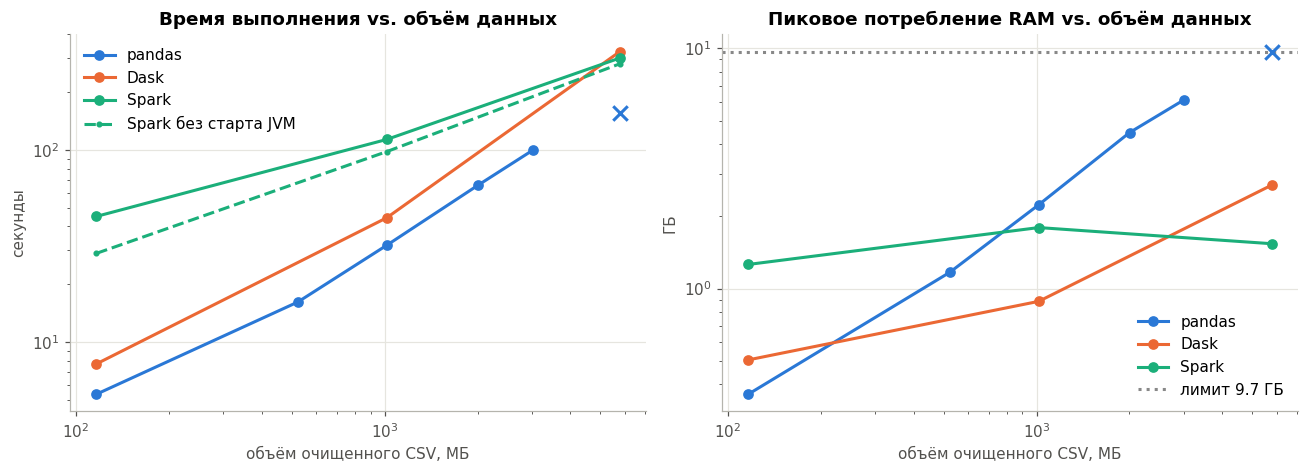

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for tool in ['pandas_csv', 'dask_csv', 'spark_csv']:
    d = perf[perf['tool'] == tool]
    ok, bad = d[d['status'] == 'ok'], d[d['status'] != 'ok']
    color = COLORS[TOOL_NAME[tool].lower()]
    for ax, col in zip(axes, ['wall_s', 'peak_gb']):
        ax.plot(ok['mb'], ok[col], marker='o', color=color, label=TOOL_NAME[tool])
        ax.scatter(bad['mb'], bad[col], marker='x', s=90, color=color, zorder=3)
spark_ok = perf[(perf['tool'] == 'spark_csv') & (perf['status'] == 'ok')]
axes[0].plot(spark_ok['mb'], spark_ok['job_s'], ls='--', marker='.', color=COLORS['spark'], label='Spark без старта JVM')
axes[1].axhline(BUDGET_GB, ls=':', color='#888', label=f'лимит {BUDGET_GB:.1f} ГБ')
for ax, title, ylabel in [(axes[0], 'Время выполнения vs. объём данных', 'секунды'),
                          (axes[1], 'Пиковое потребление RAM vs. объём данных', 'ГБ')]:
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel('объём очищенного CSV, МБ'); ax.set_ylabel(ylabel); ax.set_title(title)
    ax.legend()
plt.tight_layout(); plt.show()

Дополнительно: на срезе 1 ГБ видно, как инструменты используют процессор и диск.

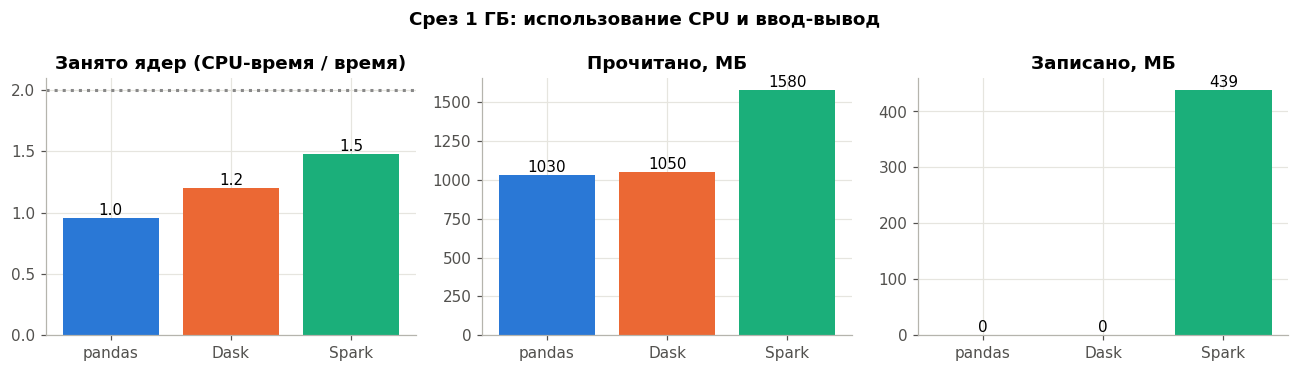

In [14]:
d = perf[(perf['slice'] == '1GB') & (perf['status'] == 'ok')].set_index('tool')
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
names = [TOOL_NAME[t] for t in d.index]
cols = [COLORS[n.lower()] for n in names]
for ax, col, title in [(axes[0], 'cores', 'Занято ядер (CPU-время / время)'),
                       (axes[1], 'read_mb', 'Прочитано, МБ'), (axes[2], 'write_mb', 'Записано, МБ')]:
    ax.bar(names, d[col], color=cols)
    ax.set_title(title)
    for i, v in enumerate(d[col]):
        ax.text(i, v, f'{v:.1f}' if col == 'cores' else f'{v:.0f}', ha='center', va='bottom')
axes[0].axhline(N_CORES, ls=':', color='#888')
plt.suptitle('Срез 1 ГБ: использование CPU и ввод-вывод', fontweight='bold')
plt.tight_layout(); plt.show()

### 4) Проанализируйте результаты:

In [15]:
def row(tool, label):
    d = perf[(perf['tool'] == tool) & (perf['slice'] == label)]
    return d.iloc[0] if len(d) else None

pd_ok = perf[(perf['tool'] == 'pandas_csv') & (perf['status'] == 'ok')]
pd_bad = perf[(perf['tool'] == 'pandas_csv') & (perf['status'] != 'ok')]
print(f'pandas: последний успешный срез {pd_ok["slice"].iloc[-1]} ({pd_ok["mb"].iloc[-1]:.0f} МБ, '
      f'пик {pd_ok["peak_gb"].iloc[-1]:.2f} ГБ)'
      + (f'; остановлен на {pd_bad["slice"].iloc[0]} ({pd_bad["mb"].iloc[0]:.0f} МБ)' if len(pd_bad) else '; ни разу не упёрся в лимит'))
print('pandas, пик RAM к объёму CSV:', ', '.join(f'{r.slice}: {r.peak_gb * 2**30 / 1e6 / r.mb:.2f}x' for r in pd_ok.itertuples()))
p1, d1, s1 = row('pandas_csv', '1GB'), row('dask_csv', '1GB'), row('spark_csv', '1GB')
if p1 is not None and p1.status == 'ok' and d1 is not None and d1.status == 'ok':
    print(f'1 ГБ: pandas {p1.wall_s:.1f} с, Dask {d1.wall_s:.1f} с -> Dask быстрее на {(p1.wall_s - d1.wall_s) / p1.wall_s * 100:.0f}% '
          f'(ускорение {p1.wall_s / d1.wall_s:.2f}x)')
else:
    print('1 ГБ: сравнить pandas и Dask нельзя, один из них не уложился в лимит памяти')
if s1 is not None and s1.status == 'ok':
    print(f'1 ГБ: Spark {s1.wall_s:.1f} с вместе со стартом JVM, {s1.job_s:.1f} с сама задача')
for label in ['100MB', 'full']:
    rr = {t: row(t, label) for t in ['pandas_csv', 'dask_csv', 'spark_csv']}
    print(f'{label}: ' + ', '.join(f'{TOOL_NAME[t]} {r.wall_s:.1f} с ({r.status})' for t, r in rr.items() if r is not None))

pandas: последний успешный срез 3GB (3016 МБ, пик 6.13 ГБ); остановлен на full (5789 МБ)
pandas, пик RAM к объёму CSV: 100MB: 3.35x, 500MB: 2.40x, 1GB: 2.36x, 2GB: 2.39x, 3GB: 2.18x
1 ГБ: pandas 32.0 с, Dask 44.4 с -> Dask быстрее на -39% (ускорение 0.72x)
1 ГБ: Spark 113.6 с вместе со стартом JVM, 98.2 с сама задача
100MB: pandas 5.4 с (ok), Dask 7.7 с (ok), Spark 45.1 с (ok)
full: pandas 156.3 с (превышен лимит RAM), Dask 325.8 с (ok), Spark 301.6 с (ok)


**Ответ на вопрос «При каком объеме данных Pandas перестает справляться?»:** pandas справился с 3 ГБ CSV (100 с, пик 6,13 ГБ) и не справился с полным датасетом 5,8 ГБ: на 156-й секунде процесс занял 9,71 ГБ и был остановлен по лимиту 9,7 ГБ. Пик памяти стабильно в 2,2-2,4 раза больше объёма CSV, поэтому полному файлу нужно около 12,7 ГБ, то есть вся RAM машины. Практическая граница: pandas справляется, пока объём CSV не больше примерно трети RAM (здесь около 4,5 ГБ). Время при этом растёт линейно, около 33 с на гигабайт, «катастрофического» роста не видно: pandas упирается в память, а не во время.

**Ответ на вопрос «На сколько процентов Dask быстрее Pandas на 1 ГБ данных?»:** Не быстрее, а на 39% медленнее: 44,4 с против 32,0 с (ускорение 0,72x). На двух ядрах Dask занимает в среднем 1,2 ядра, а его накладные расходы (граф задач, объединение частичных агрегатов, отдельный подсчёт `nunique`) съедают выигрыш от параллелизма. Зато Dask тратит в 2,5 раза меньше памяти (0,88 ГБ против 2,23 ГБ) и обработал полный датасет за 326 с при пике 2,7 ГБ, где pandas не уложился.

**Ответ на вопрос «Как соотносится время выполнения Spark с другими инструментами?»:** На малых и средних объёмах Spark самый медленный: 45 с на 100 МБ (в 8 раз дольше pandas) и 114 с на 1 ГБ (в 3,5 раза дольше pandas и в 2,6 раза дольше Dask). Около 15-20 с из этого занимает запуск JVM, остальное это два шаффла с записью на диск. На полном датасете Spark и Dask сравнялись: 302 с против 326 с, без запуска JVM Spark быстрее Dask на 14% (281 с). При этом память Spark почти не зависит от объёма (1,3-1,8 ГБ).

**Анализ причин различий в производительности:** - **pandas** работает в одном потоке (0,95 ядра из 2) и держит в памяти всю таблицу со всеми 9 столбцами. Отсюда минимальные накладные расходы на малых данных и рост памяти пропорционально объёму.
- **Dask** читает файл блоками по 64 МБ и держит в памяти только частичные агрегаты, поэтому на полном датасете его пик 0,5 от объёма CSV. Но на двух ядрах параллелизм почти не работает (1,1-1,2 ядра): разбор CSV в pandas частично держит GIL.
- **Spark** читает только 4 нужных столбца (`ReadSchema`), но для `COUNT DISTINCT` делает два шаффла: на полном датасете это 2,26 ГБ записи на диск и 7,1 ГБ чтения при 5,8 ГБ исходного CSV. Он загружает процессор лучше всех (1,5 ядра, 73%), но много работы уходит на сериализацию и шаффл, которые нужны для распределения по узлам, а на одной машине с двумя ядрами не окупаются.

**Вывод о том, при каких условиях каждый инструмент предпочтителен:** pandas предпочтителен, пока CSV не больше примерно трети RAM: на таких объёмах он быстрее всех и проще всего. Dask нужен, когда данные не помещаются в память одной машины, а код хочется оставить на pandas API: он медленнее, но обрабатывает объём больше RAM при малом расходе памяти. Spark оправдан, когда данных больше, чем может обработать одна машина, нужен кластер, отказоустойчивость или общий движок с потоковой обработкой. На одной машине с двумя ядрами он по времени лишь догоняет Dask на полном датасете.

## Часть 3: Анализ физического плана выполнения в Spark

### 1) Для вашей Spark-реализации задачи:

Физический план строится для полного очищенного CSV без запуска (`explain` только планирует). Для разбора стадий используются метрики реального запуска на полном датасете из Части 2: процесс Spark перед завершением сохранил их из REST API Spark UI в `work/metrics_spark_full.json`.

In [16]:
spark = start_spark()


def agg_spark(df):
    return df.groupBy(*KEY).agg(F.count('*').alias('events'), F.countDistinct('user_id').alias('users'),
                                F.sum('price').alias('revenue'), F.avg('price').alias('avg_price'))


full_df = spark.read.csv(CLEAN_CSV, header=True, schema=SCHEMA)
agg_spark(full_df).explain('formatted')

== Physical Plan ==
AdaptiveSparkPlan (8)
+- HashAggregate (7)
   +- Exchange (6)
      +- HashAggregate (5)
         +- HashAggregate (4)
            +- Exchange (3)
               +- HashAggregate (2)
                  +- Scan csv  (1)


(1) Scan csv 
Output [4]: [event_type#1, brand#5, price#6, user_id#7L]
Batched: false
Location: InMemoryFileIndex [file:/content/work/clean_csv]
ReadSchema: struct<event_type:string,brand:string,price:double,user_id:bigint>

(2) HashAggregate
Input [4]: [event_type#1, brand#5, price#6, user_id#7L]
Keys [3]: [brand#5, event_type#1, user_id#7L]
Functions [3]: [partial_count(1), partial_sum(price#6), partial_avg(price#6)]
Aggregate Attributes [3]: [count(1)#22L, sum(price#6)#24, avg(price#6)#25]
Results [7]: [brand#5, event_type#1, user_id#7L, count#28L, sum#30, sum#33, count#34L]

(3) Exchange
Input [7]: [brand#5, event_type#1, user_id#7L, count#28L, sum#30, sum#33, count#34L]
Arguments: hashpartitioning(brand#5, event_type#1, user_id#7L, 200), ENSURE_

### 2) Проанализируйте физический план:

In [17]:
with open(f'{WORK}/metrics_spark_full.json') as fh:
    stages_full = json.load(fh)


def q(ts, metric, sub=None, i=None):
    v = ts[sub][metric] if sub else ts[metric]
    return v if i is None else v[i]


def stage_ops(s):
    if s['inputBytes'] > 0:
        return 'Scan + HashAggregate (partial) + запись Exchange'
    if s['shuffleReadBytes'] > 0 and s['shuffleWriteBytes'] > 0:
        return 'чтение Exchange + HashAggregate (merge, partial distinct) + запись Exchange'
    if s['shuffleReadBytes'] > 0:
        return 'чтение Exchange + HashAggregate (final)'
    return 'служебная: список входных файлов'


def stage_table(stages):
    rows = []
    for s in sorted(stages, key=lambda s: s['stageId']):
        ts = s['taskSummary']
        rows.append({
            'Стадия': s['stageId'], 'Операции': stage_ops(s), 'Задач': s['numTasks'],
            'Время задач, с': s['executorRunTime'] / 1000,
            'Чтение входа, МБ': s['inputBytes'] / 1e6, 'Строк входа': s['inputRecords'],
            'Shuffle read, МБ': s['shuffleReadBytes'] / 1e6, 'Строк shuffle read': s['shuffleReadRecords'],
            'Shuffle write, МБ': s['shuffleWriteBytes'] / 1e6, 'Строк shuffle write': s['shuffleWriteRecords'],
            'Spill на диск, МБ': s.get('diskBytesSpilled', 0) / 1e6,
            'GC, с': s.get('jvmGcTime', 0) / 1000,
            'Задача: медиана, мс': q(ts, 'executorRunTime', i=2), 'Задача: макс, мс': q(ts, 'executorRunTime', i=5),
            'Shuffle read на задачу: медиана, строк': q(ts, 'readRecords', 'shuffleReadMetrics', 2),
            'Shuffle read на задачу: макс, строк': q(ts, 'readRecords', 'shuffleReadMetrics', 5),
        })
    t = pd.DataFrame(rows)
    t['Доля времени, %'] = (t['Время задач, с'] / t['Время задач, с'].sum() * 100).round(1)
    t['Макс / медиана задачи'] = (t['Задача: макс, мс'] / t['Задача: медиана, мс'].clip(lower=1)).round(1)
    return t


st_full = stage_table(stages_full)
display(st_full.round(1).T)

,0,1,2,3
Стадия,0,1,3,6
Операции,служебная: список входных файлов,Scan + HashAggregate (partial) + запись Exchange,"чтение Exchange + HashAggregate (merge, partial distinct) + запись Exchange",чтение Exchange + HashAggregate (final)
Задач,200,200,200,21
"Время задач, с",1.2,401.6,112.1,2.7
"Чтение входа, МБ",0.0,5834.0,0.0,0.0
Строк входа,0,42349872,0,0
"Shuffle read, МБ",0.0,0.0,1106.7,22.6
Строк shuffle read,0,0,40675113,479861
"Shuffle write, МБ",0.0,1106.7,22.6,0.0
Строк shuffle write,0,40675113,479861,0


Как план ложится на стадии. Стадии разделены операторами `Exchange`, то есть шаффлами. Кроме них в списке есть служебная стадия без данных: Spark составляет список из 200 входных файлов отдельным заданием (при числе файлов больше 32 он делает это параллельно). Номера стадий в таблице выше идут из Spark UI, пропущенные номера принадлежат стадиям, которые AQE пометил как пропущенные.

| Стадия | Операторы плана | Что делает |
|---|---|---|
| чтение | `Scan csv` -> `HashAggregate` (keys = brand, event_type, user_id; partial_count, partial_sum) -> запись `Exchange` | читает CSV, разбирает только 4 нужных столбца (`ReadSchema`), частично агрегирует по ключу вместе с `user_id` |
| промежуточная | чтение `Exchange` hashpartitioning(brand, event_type, user_id, 200) -> `HashAggregate` (merge) -> `HashAggregate` (partial_count(distinct user_id)) -> запись `Exchange` | сводит пары «ключ, пользователь» со всех задач, после чего каждая пара уникальна, и считает частичное число пользователей на ключ |
| финальная | чтение `Exchange` hashpartitioning(brand, event_type, 200) -> `HashAggregate` (final) | складывает частичные счётчики по ключу |

Для `COUNT DISTINCT` Catalyst переписывает агрегацию в два уровня. Сначала группировка идёт по (ключ, `user_id`), а уже потом по ключу. Поэтому шаффлов два, а не один, как у простого `count/sum`.

**Ответ на вопрос «Сколько этапов выполнения (stages)?»:** в полном запуске 4 стадии. Три работают с данными: чтение с частичной агрегацией (стадия 1), промежуточная агрегация (стадия 3) и финальная (стадия 6). Ещё одна служебная (стадия 0) составляет список файлов. Стадий с данными три, потому что `COUNT DISTINCT` даёт два шаффла.

**Ответ на вопрос «Какие операции выполняются в каждом этапе?»:** в таблице выше.

**Ответ на вопрос «Есть ли операции shuffle? Если да, то сколько данных передается?»:** да, два. Первый передаёт 1 106,7 МБ (40,7 млн строк): частичная агрегация по (ключ, `user_id`) сократила 42,3 млн строк всего на 4%, потому что почти каждая пара «ключ, пользователь» внутри задачи уникальна. Второй передаёт уже 22,6 МБ (479 861 строка): после него на каждый ключ в каждой задаче остаётся по одной строке.

### 3) Выявите потенциальные узкие места:

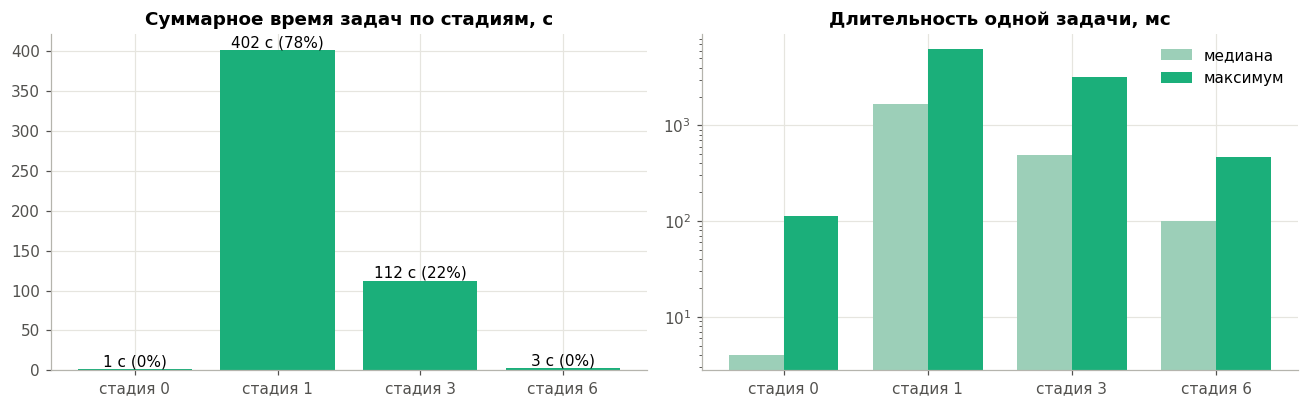

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
labels = [f'стадия {sid}' for sid in st_full['Стадия']]
axes[0].bar(labels, st_full['Время задач, с'], color=COLORS['spark'])
axes[0].set_title('Суммарное время задач по стадиям, с')
for i, v in enumerate(st_full['Время задач, с']):
    axes[0].text(i, v, f'{v:.0f} с ({st_full["Доля времени, %"].iloc[i]:.0f}%)', ha='center', va='bottom')
w = 0.38
x = np.arange(len(st_full))
axes[1].bar(x - w / 2, st_full['Задача: медиана, мс'], w, label='медиана', color='#9ccfb8')
axes[1].bar(x + w / 2, st_full['Задача: макс, мс'], w, label='максимум', color=COLORS['spark'])
axes[1].set_xticks(x, labels); axes[1].set_yscale('log')
axes[1].set_title('Длительность одной задачи, мс'); axes[1].legend()
plt.tight_layout(); plt.show()

**Ответ на вопрос «Сколько данных обрабатывается на каждом этапе?»:** стадия 1 читает 5 834 МБ (42,3 млн строк) и пишет в шаффл 1 107 МБ; стадия 3 читает эти 1 107 МБ и пишет 22,6 МБ; стадия 6 читает 22,6 МБ и выдаёт 6 014 групп. Объём падает в 5 раз на первом шаффле и ещё в 49 раз на втором.

**Ответ на вопрос «Есть ли дисбаланс нагрузки между узлами (skew)?»:** по данным нет. В стадии 3 задача читает от 203 309 до 207 780 строк, разница 2%, в стадии 6 медиана 21 934 и максимум 36 028 строк. Первый шаффл идёт по (ключ, `user_id`), а не по ключу, поэтому горячие ключи размазаны по всем партициям. По времени разброс есть (максимум к медиане 3,7 в стадии 1 и 6,6 в стадии 3), но при одинаковом объёме он вызван конкуренцией двух потоков за ядра и сборкой мусора, а не перекосом данных. Перекос по ключу проявится, если разложить данные по самому ключу, это проверяется в Части 4.

**Ответ на вопрос «Какие операции занимают больше всего времени?»:** стадия 1: 402 с суммарного времени задач из 518 (78%). В ней разбор CSV, хэш-агрегация 42 млн строк по (ключ, `user_id`) и запись 1,1 ГБ в шаффл. Стадия 3 занимает 22%, финальная меньше 1%.

### 4) Предложите гипотезы об оптимизации на основе анализа плана

1. **Parquet вместо CSV.** 78% времени уходит на стадию чтения, а в ней основная работа это разбор текста CSV. Parquet хранит столбцы в бинарном виде и позволяет прочитать только 4 нужных столбца из 9.
2. **Меньше партиций шаффла.** 200 партиций на результат в 6 014 строк дают 200 коротких задач в стадии 3 (медиана 0,5 с). AQE в финальной стадии сам ужал 200 партиций до 21, то есть 200 явно избыточно. На двух ядрах должно хватить 2-4 x числа ядер.
3. **AQE.** Он уже объединяет мелкие партиции после шаффла; явное включение должно дать часть выигрыша п. 2 без ручного подбора.
4. **Крупнее сплиты при чтении.** Из-за `spark.default.parallelism = 200` CSV режется на 200 частей независимо от числа ядер, лишние задачи стоят времени на запуск.
5. **Соль не нужна базовому плану**: шаффл и так сбалансирован. Она понадобится, только если данные раскладываются по ключу.

Гипотезы проверяются в Частях 4 и 5.

## Часть 4: Выявление и устранение skew

### 1) Проверьте наличие skew в вашей задаче:

Распределение ключа группировки берётся из результата Spark на полном датасете (Часть 2): там уже посчитано число событий на каждый ключ (бренд, тип события).

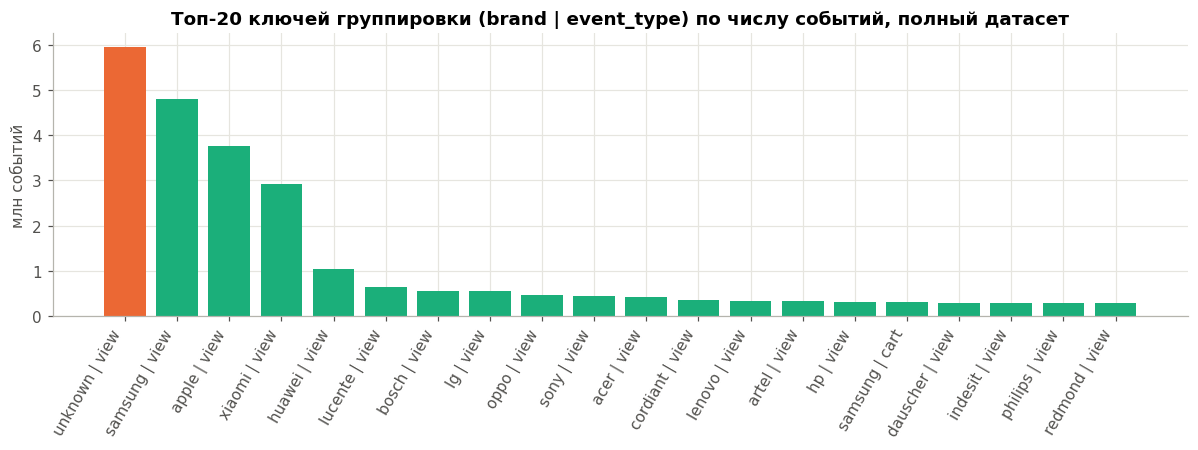

,Показатель,Значение
0,Ключей (групп),6014
1,Среднее событий на ключ,7042
2,Медиана событий на ключ,72
3,Максимум (ключ),5 967 215 (unknown | view)
4,Коэффициент вариации (std / mean),17.0
5,Максимум / медиана,82878
6,"Доля самого крупного ключа, %",14.1
7,"Доля топ-5 ключей, %",43.7
8,"Доля ключей, дающих 80% событий, %",2.01


In [19]:
key_dist = load_out(f'{OUT}/spark_csv_full.csv').reset_index().sort_values('events', ascending=False)
key_dist['ключ'] = key_dist['brand'] + ' | ' + key_dist['event_type']
top = key_dist.head(20)
plt.figure(figsize=(11, 4.2))
plt.bar(top['ключ'], top['events'] / 1e6, color=[COLORS['dask'] if b == 'unknown' else COLORS['spark'] for b in top['brand']])
plt.xticks(rotation=60, ha='right')
plt.ylabel('млн событий')
plt.title('Топ-20 ключей группировки (brand | event_type) по числу событий, полный датасет')
plt.tight_layout(); plt.show()

ev_k = key_dist['events']
skew = pd.DataFrame([
    ('Ключей (групп)', len(ev_k)),
    ('Среднее событий на ключ', round(ev_k.mean())),
    ('Медиана событий на ключ', round(ev_k.median())),
    ('Максимум (ключ)', f'{ev_k.iloc[0]:,} ({key_dist["ключ"].iloc[0]})'.replace(',', ' ')),
    ('Коэффициент вариации (std / mean)', round(ev_k.std() / ev_k.mean(), 1)),
    ('Максимум / медиана', round(ev_k.iloc[0] / ev_k.median())),
    ('Доля самого крупного ключа, %', round(ev_k.iloc[0] / ev_k.sum() * 100, 1)),
    ('Доля топ-5 ключей, %', round(ev_k.head(5).sum() / ev_k.sum() * 100, 1)),
    ('Доля ключей, дающих 80% событий, %', round((ev_k.cumsum() / ev_k.sum() <= 0.8).sum() / len(ev_k) * 100, 2)),
], columns=['Показатель', 'Значение'])
display(skew)

### 2) Если skew обнаружен:

Степень skew видна выше по коэффициенту вариации и отношению максимума к медиане. Чтобы оценить влияние skew на производительность, сравниваю на срезе 1 ГБ три варианта одной и той же агрегации:
- **базовый:** план из Части 3, двухуровневая агрегация с первым шаффлом по (ключ, `user_id`);
- **`repartition` по ключу перед группировкой:** частый совет «разложить данные по ключу заранее». Здесь все строки одного ключа попадают в одну партицию, и после этого Spark не делает своего шаффла;
- **с солью** (пункт 3).

Опыты идут на срезе 1 ГБ, а не на полном датасете. Запуск на полном объёме в несколько раз дольше, чем на срезе, а каждый вариант нужно повторить трижды. Распределение ключей на срезе такое же, как на полном объёме, потому что срез состоит из случайных файлов. AQE в этих опытах выключен, чтобы он не перестраивал партиции и не смешивал эффекты. Время считается медианой из трёх запусков. Метрики задач берутся из REST API Spark UI для последнего запуска.

In [20]:
SPARK_UI = f'{spark.sparkContext.uiWebUrl}/api/v1/applications/{spark.sparkContext.applicationId}'


def ui_get(path):
    return json.load(urllib.request.urlopen(f'{SPARK_UI}/{path}'))


def jvm_cpu_seconds():
    return sum(sum(p.cpu_times()[:2]) for p in psutil.Process().children(recursive=True) if p.name().startswith('java'))


def spark_job(name, build, repeats=3):
    """Запускает запрос repeats раз, возвращает медиану времени, CPU JVM и метрики стадий последнего запуска."""
    sc = spark.sparkContext
    times, cpus = [], []
    for i in range(repeats):
        group = f'{name}_{i}'
        sc.setJobGroup(group, group)
        c0 = jvm_cpu_seconds()
        t0 = time.perf_counter()
        res = build().toPandas()
        times.append(time.perf_counter() - t0)
        cpus.append(jvm_cpu_seconds() - c0)
    stages = []
    for job_id in sc.statusTracker().getJobIdsForGroup(group):
        for sid in ui_get(f'jobs/{job_id}')['stageIds']:
            for s in ui_get(f'stages/{sid}'):
                if s['status'] == 'COMPLETE':
                    s['taskSummary'] = ui_get(f"stages/{sid}/{s['attemptId']}/taskSummary?quantiles=0,0.25,0.5,0.75,0.95,1")
                    stages.append(s)
    return {'name': name, 'time_s': statistics.median(times), 'times': [round(t, 1) for t in times],
            'cpu_s': statistics.median(cpus), 'stages': stage_table(stages) if stages else None,
            'result': res.sort_values(KEY).reset_index(drop=True)}


def set_conf(conf):
    for k, v in conf.items():
        if v is None:
            spark.conf.unset(k)
        else:
            spark.conf.set(k, v)


BASE_CONF = {'spark.sql.shuffle.partitions': '200', 'spark.sql.adaptive.enabled': 'false',
             'spark.sql.files.minPartitionNum': None}
set_conf(BASE_CONF)
g1 = spark.read.csv(SLICES['1GB'], header=True, schema=SCHEMA)
spark_job('warmup', lambda: agg_spark(g1), repeats=1)
skew_base = spark_job('base', lambda: agg_spark(g1))
skew_rep = spark_job('repartition_key', lambda: agg_spark(g1.repartition(200, *KEY)))


def heavy_stage(r):
    t = r['stages']
    return t.loc[t['Строк shuffle read'].idxmax()]


def skew_cmp(runs, names):
    t = pd.DataFrame({name: {
        'Время запроса, с (медиана)': round(r['time_s'], 1), 'Запуски, с': r['times'], 'CPU JVM, с': round(r['cpu_s'], 1),
        'Стадий': len(r['stages']),
        'Стадия с наибольшим shuffle read: задач': heavy_stage(r)['Задач'],
        'строк на задачу: медиана': heavy_stage(r)['Shuffle read на задачу: медиана, строк'],
        'строк на задачу: максимум': heavy_stage(r)['Shuffle read на задачу: макс, строк'],
        'макс / медиана строк': round(heavy_stage(r)['Shuffle read на задачу: макс, строк']
                                      / max(heavy_stage(r)['Shuffle read на задачу: медиана, строк'], 1), 1),
        'время задачи: медиана, мс': heavy_stage(r)['Задача: медиана, мс'],
        'время задачи: максимум, мс': heavy_stage(r)['Задача: макс, мс'],
    } for r, name in zip(runs, names)})
    return t


display(skew_cmp([skew_base, skew_rep], ['базовый', 'repartition по ключу']))

,базовый,repartition по ключу
"Время запроса, с (медиана)",55.9,48.3
"Запуски, с","[85.3, 55.9, 53.3]","[50.3, 46.9, 48.3]"
"CPU JVM, с",84.3,74.3
Стадий,3,2
Стадия с наибольшим shuffle read: задач,200,200
строк на задачу: медиана,36256.0,12341.0
строк на задачу: максимум,37148.0,1097692.0
макс / медиана строк,1.0,88.9
"время задачи: медиана, мс",111.0,56.0
"время задачи: максимум, мс",360.0,5121.0


**Коэффициент skew и его интерпретация:** по 6 014 ключам коэффициент вариации (std / mean) равен 17,0, а максимум больше медианы в 82 878 раз. Самый крупный ключ `unknown | view` даёт 14,1% всех событий, топ-5 ключей 43,7%, а 80% событий приходится на 2% ключей. Это сильный skew: при разбиении по ключу одна партиция получит седьмую часть всех данных.

**Влияние skew на производительность:** в базовом плане его нет: в самой нагруженной стадии задачи получают по 36-37 тыс. строк, максимум к медиане 1,0. При `repartition` по ключу перекос становится реальным: медиана 12 341 строка на задачу, максимум 1 097 692 (в 89 раз больше), самая долгая задача идёт 5,1 с при медиане 56 мс. При этом весь запрос получился даже быстрее базового (48,3 с против 55,9 с): шаффлов на один меньше, а на двух ядрах длинная задача идёт параллельно с остальными 199. На кластере с десятками исполнителей время такой стадии определялось бы этой одной задачей.

### 3) Реализуйте одну из стратегий устранения skew:

Выбрана стратегия **добавления «соли» к ключу группировки**. Broadcast join здесь неприменим, так как соединения в задаче нет. Фильтрация горячих ключей выбросила бы `unknown`, samsung и apple, а это самые крупные группы и треть всех событий.

Соль считается как `xxhash64(user_id) mod N`, а не как случайное число (`rand()` из лекции). Причина в уникальных пользователях: все события одного пользователя должны попасть в одну и ту же «солёную» подгруппу. Тогда множества пользователей в подгруппах не пересекаются, и сумма уникальных по подгруппам точно равна числу уникальных по ключу. Со случайной солью один пользователь попал бы в несколько подгрупп и был бы посчитан несколько раз. Средняя цена после второго шага пересчитывается как выручка / события, а не как среднее средних.

Число частей соли N подбирается так, чтобы самый крупный ключ после разбиения был не больше средней партиции: N = доля крупнейшего ключа x число партиций, с округлением вверх до степени двойки.

In [21]:
top_share = ev_k.iloc[0] / ev_k.sum()
SALT = 2 ** math.ceil(math.log2(top_share * 200))
print(f'Доля крупнейшего ключа {top_share:.1%} x 200 партиций = {top_share * 200:.1f} -> N = {SALT}')


def agg_salted(df, n=SALT):
    salted = df.withColumn('salt', F.pmod(F.xxhash64('user_id'), F.lit(n)))
    part = (salted.repartition(200, *KEY, 'salt')
                  .groupBy(*KEY, 'salt')
                  .agg(F.count('*').alias('events'), F.countDistinct('user_id').alias('users'),
                       F.sum('price').alias('revenue')))
    return (part.groupBy(*KEY)
                .agg(F.sum('events').alias('events'), F.sum('users').alias('users'), F.sum('revenue').alias('revenue'))
                .withColumn('avg_price', F.col('revenue') / F.col('events')))


skew_salt = spark_job('salted', lambda: agg_salted(g1))
same = (skew_salt['result'][KEY + ['events', 'users']].equals(skew_base['result'][KEY + ['events', 'users']])
        and np.allclose(skew_salt['result']['revenue'], skew_base['result']['revenue'], rtol=1e-9))
print('Результат с солью совпадает с базовым:', same)

Доля крупнейшего ключа 14.1% x 200 партиций = 28.2 -> N = 32
Результат с солью совпадает с базовым: True


### 4) Измерьте эффект оптимизации:

,базовый,repartition по ключу,repartition по ключу + соль
"Время запроса, с (медиана)",55.9,48.3,57.6
"Запуски, с","[85.3, 55.9, 53.3]","[50.3, 46.9, 48.3]","[57.6, 58.2, 56.8]"
"CPU JVM, с",84.3,74.3,88.1
Стадий,3,2,3
Стадия с наибольшим shuffle read: задач,200,200,200
строк на задачу: медиана,36256.0,12341.0,28063.0
строк на задачу: максимум,37148.0,1097692.0,122855.0
макс / медиана строк,1.0,88.9,4.4
"время задачи: медиана, мс",111.0,56.0,143.0
"время задачи: максимум, мс",360.0,5121.0,474.0


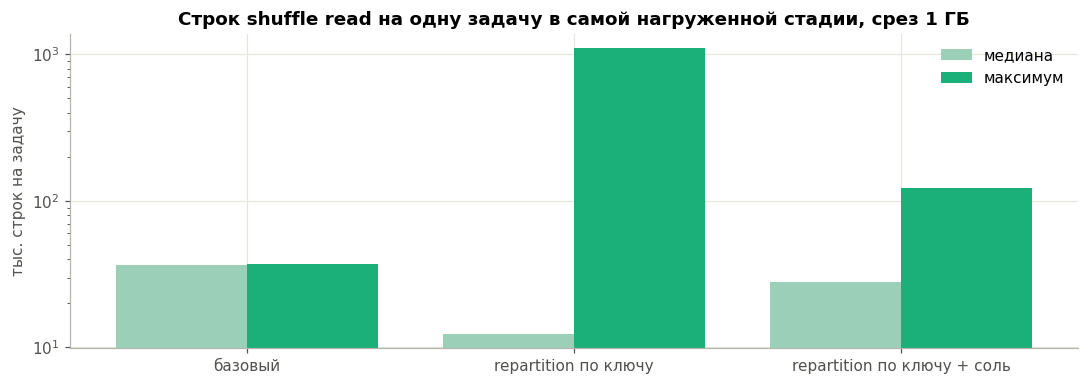

In [22]:
cmp = skew_cmp([skew_base, skew_rep, skew_salt], ['базовый', 'repartition по ключу', 'repartition по ключу + соль'])
display(cmp)

fig, ax = plt.subplots(figsize=(10, 3.6))
for i, (r, name) in enumerate(zip([skew_base, skew_rep, skew_salt], cmp.columns)):
    h = heavy_stage(r)
    ax.bar(i - 0.2, h['Shuffle read на задачу: медиана, строк'] / 1e3, 0.4, color='#9ccfb8', label='медиана' if i == 0 else None)
    ax.bar(i + 0.2, h['Shuffle read на задачу: макс, строк'] / 1e3, 0.4, color=COLORS['spark'], label='максимум' if i == 0 else None)
ax.set_xticks(range(3), cmp.columns); ax.set_yscale('log')
ax.set_ylabel('тыс. строк на задачу'); ax.legend()
ax.set_title('Строк shuffle read на одну задачу в самой нагруженной стадии, срез 1 ГБ')
plt.tight_layout(); plt.show()

Изменения в физическом плане: у варианта с солью появляется вычисление `salt` и второй уровень агрегации, а шаффл идёт по (ключ, salt) вместо ключа.

In [23]:
print('=== repartition по ключу ===')
agg_spark(g1.repartition(200, *KEY)).explain()
print('=== repartition по ключу + соль ===')
agg_salted(g1).explain()

=== repartition по ключу ===
== Physical Plan ==
*(1) HashAggregate(keys=[brand#44, event_type#40], functions=[count(1), sum(price#45), avg(price#45), count(distinct user_id#46L)])
+- *(1) HashAggregate(keys=[brand#44, event_type#40], functions=[merge_count(1), merge_sum(price#45), merge_avg(price#45), partial_count(distinct user_id#46L)])
   +- *(1) HashAggregate(keys=[brand#44, event_type#40, user_id#46L], functions=[merge_count(1), merge_sum(price#45), merge_avg(price#45)])
      +- *(1) HashAggregate(keys=[brand#44, event_type#40, user_id#46L], functions=[partial_count(1), partial_sum(price#45), partial_avg(price#45)])
         +- Exchange hashpartitioning(brand#44, event_type#40, 200), REPARTITION_BY_NUM, [plan_id=540]
            +- FileScan csv [event_type#40,brand#44,price#45,user_id#46L] Batched: false, DataFilters: [], Format: CSV, Location: InMemoryFileIndex(35 paths)[file:/content/work/clean_csv/part-00000-e83f610c-279a-40fd-bf8e-979c3..., PartitionFilters: [], PushedFilter

**Измерение эффекта оптимизации с цифрами:** Соль на 32 части убрала перекос: максимум строк на задачу снизился с 1 097 692 до 122 855 (в 9 раз), отношение максимума к медиане с 88,9 до 4,4, а самая долгая задача с 5 121 мс до 474 мс (в 10,8 раза). Результат совпадает с базовым точно.

Время запроса при этом выросло с 48,3 с до 57,6 с (на 19%) и вернулось к уровню базового плана (55,9 с). В плане появились вычисление `salt`, шаффл по (ключ, `salt`) и второй уровень агрегации с ещё одним небольшим шаффлом по ключу. Вывод: на двух ядрах соль не ускоряет запрос, потому что медленная задача не задерживала остальные. Она выравнивает нагрузку и окупится там, где время стадии определяет самая медленная задача, то есть на кластере. Для этой задачи лучшая защита от skew это базовый план Spark, в котором разбиение идёт по (ключ, `user_id`).

## Часть 5: Оптимизация Spark-кода

### 1) Примените минимум 3 оптимизации:

Каждая оптимизация проверяется на срезе 1 ГБ отдельно от остальных, относительно одной и той же исходной конфигурации: CSV, `spark.sql.shuffle.partitions = 200`, AQE выключен. Почему срез, а не полный объём, объяснено в Части 4. Лучшая комбинация в конце проверяется на полном датасете.

Проверяемые оптимизации и гипотезы из Части 3:
1. **`spark.sql.shuffle.partitions`:** 200 партиций на результат в несколько тысяч строк дают сотни мелких задач. Лекция рекомендует 2-4 x число ядер. Проверяются значения N, 2N, 4N (N = число ядер) и 800;
2. **`repartition()` перед группировкой:** уже измерен в Части 4 (вариант «repartition по ключу»);
3. **adaptive query execution:** AQE после первого шаффла видит реальные размеры партиций и объединяет мелкие;
4. **Parquet вместо CSV:** колоночный формат читает только 4 нужных столбца из 9 и не разбирает текст;
5. **крупные сплиты при чтении (`spark.sql.files.minPartitionNum` = числу ядер), специфично для этого сценария.** Задание требует `spark.default.parallelism = 200`. От этого параметра Spark считает размер сплита: объём / 200, то есть около 5 МБ на 1 ГБ. Получаются сотни коротких задач чтения, у каждой свои накладные расходы на запуск и сжатие шаффла. Если поднять размер сплита, задач чтения станет примерно по числу ядер.

### 2) Измерьте эффект каждой оптимизации отдельно:

In [24]:
g1_pq = spark.read.parquet(PQ_SLICES['1GB'])
EXPERIMENTS = [
    ('Исходная (CSV, 200 партиций, AQE выкл.)', {}, lambda: agg_spark(g1)),
    *[(f'shuffle.partitions = {p}', {'spark.sql.shuffle.partitions': str(p)}, lambda: agg_spark(g1))
      for p in sorted({N_CORES, 2 * N_CORES, 4 * N_CORES, 800})],
    ('AQE включён', {'spark.sql.adaptive.enabled': 'true'}, lambda: agg_spark(g1)),
    ('Parquet вместо CSV', {}, lambda: agg_spark(g1_pq)),
    (f'minPartitionNum = {N_CORES} (крупные сплиты)', {'spark.sql.files.minPartitionNum': str(N_CORES)}, lambda: agg_spark(g1)),
]
opt_runs = []
for name, conf, build in EXPERIMENTS:
    set_conf({**BASE_CONF, **conf})
    r = spark_job(name, build)
    r['conf'] = conf
    opt_runs.append(r)
    print(f"{name:45s} {r['time_s']:6.1f} с  {r['times']}")
set_conf(BASE_CONF)
rep = dict(skew_rep, name='repartition() по ключу перед группировкой (Часть 4)', conf={})
opt_runs.insert([r['name'] for r in opt_runs].index('AQE включён'), rep)

base_t, base_cpu = opt_runs[0]['time_s'], opt_runs[0]['cpu_s']
one_off = {'Parquet вместо CSV': conv_s['1GB']}
opt = pd.DataFrame([{
    'Оптимизация': r['name'], 'Время, с (медиана)': round(r['time_s'], 1), 'Запуски, с': r['times'],
    'Ускорение, x': round(base_t / r['time_s'], 2), 'Выигрыш по времени, %': round((base_t - r['time_s']) / base_t * 100, 1),
    'CPU JVM, с': round(r['cpu_s'], 1), 'Изменение CPU, %': round((r['cpu_s'] - base_cpu) / base_cpu * 100, 1),
    'Задач всего': int(r['stages']['Задач'].sum()),
    'Shuffle write, МБ': round(r['stages']['Shuffle write, МБ'].sum(), 1),
    'Разовые затраты, с': round(one_off.get(r['name'], 0), 1),
} for r in opt_runs])
display(opt)

Исходная (CSV, 200 партиций, AQE выкл.)         64.6 с  [61.5, 64.6, 75.0]
shuffle.partitions = 2                          46.8 с  [46.8, 48.6, 41.4]
shuffle.partitions = 4                          39.2 с  [38.0, 39.2, 43.1]
shuffle.partitions = 8                          42.6 с  [43.7, 36.6, 42.6]
shuffle.partitions = 800                        96.8 с  [96.8, 102.6, 83.6]
AQE включён                                     50.8 с  [49.8, 55.8, 50.8]
Parquet вместо CSV                              35.0 с  [37.9, 35.0, 34.0]
minPartitionNum = 2 (крупные сплиты)            45.2 с  [44.5, 49.2, 45.2]


,Оптимизация,"Время, с (медиана)","Запуски, с","Ускорение, x","Выигрыш по времени, %","CPU JVM, с","Изменение CPU, %",Задач всего,"Shuffle write, МБ","Разовые затраты, с"
0,"Исходная (CSV, 200 партиций, AQE выкл.)",64.6,"[61.5, 64.6, 75.0]",1.00,0.0,97.8,0.0,576,218.5,0.0
1,shuffle.partitions = 2,46.8,"[46.8, 48.6, 41.4]",1.38,27.6,72.1,-26.3,180,188.3,0.0
2,shuffle.partitions = 4,39.2,"[38.0, 39.2, 43.1]",1.65,39.4,60.0,-38.7,184,189.3,0.0
3,shuffle.partitions = 8,42.6,"[43.7, 36.6, 42.6]",1.52,34.0,66.6,-31.9,192,190.7,0.0
4,shuffle.partitions = 800,96.8,"[96.8, 102.6, 83.6]",0.67,-49.8,144.3,47.6,1776,286.2,0.0
5,repartition() по ключу перед группировкой (Часть 4),48.3,"[50.3, 46.9, 48.3]",1.34,25.2,74.3,-24.0,376,107.0,0.0
6,AQE включён,50.8,"[49.8, 55.8, 50.8]",1.27,21.4,75.0,-23.3,387,218.3,0.0
7,Parquet вместо CSV,35.0,"[37.9, 35.0, 34.0]",1.85,45.8,51.8,-47.0,576,218.5,60.0
8,minPartitionNum = 2 (крупные сплиты),45.2,"[44.5, 49.2, 45.2]",1.43,30.0,70.5,-27.9,409,196.8,0.0


**Таблица с результатами каждой оптимизации:** выше. Исходная конфигурация дала 64,6 с. Та же конфигурация в Части 4 дала 55,9 с, то есть разброс между сериями запусков около 15%. Эффекты меньше 15% по одному сравнению надёжными считать нельзя.

- **Parquet вместо CSV** дал наибольший выигрыш: 35,0 с (-46%), CPU на 47% меньше. Разовые затраты на конвертацию 60 с окупаются за два запуска (экономия 29,6 с на запуск).
- **`shuffle.partitions`**: 4 партиции 39,2 с (-39%), 8 партиций 42,6 с (-34%), 2 партиции 46,8 с (-28%). 800 партиций замедлили запрос в 1,5 раза (96,8 с): 1 776 задач вместо 576.
- **AQE** дал -21%: он сам объединил партиции после шаффла (387 задач вместо 576).
- **Крупные сплиты** (`minPartitionNum = 2`) дали -30%, но этот результат на границе разброса.
- **`repartition()` по ключу** дал -25% за счёт одного шаффла вместо двух, но ценой перекоса в 89 раз (Часть 4).

Все полезные оптимизации снижают и время, и CPU: на графике ниже они в левом верхнем углу.

### 3) Постройте график "затраты vs. выгода" для каждой оптимизации

Затраты и выгода измеряются, а не оцениваются на глаз:
- **выгода** = сокращение времени запроса относительно исходной конфигурации, %;
- **затраты на запуск** = изменение процессорного времени JVM, %. Это ресурс, за который платят в облаке;
- **разовые затраты** (размер точки) = время на подготовку. Для Parquet это конвертация среза из CSV, у остальных оптимизаций только строка конфигурации.

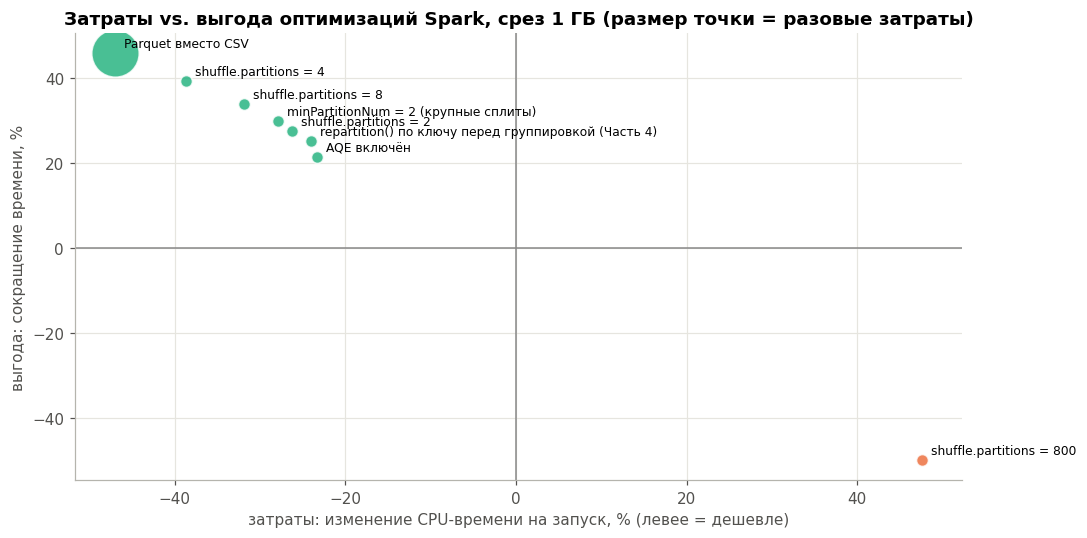

In [25]:
fig, ax = plt.subplots(figsize=(10, 5))
for _, r in opt.iloc[1:].iterrows():
    size = 60 + r['Разовые затраты, с'] * 15
    color = COLORS['spark'] if r['Выигрыш по времени, %'] > 0 else COLORS['dask']
    ax.scatter(r['Изменение CPU, %'], r['Выигрыш по времени, %'], s=size, color=color, alpha=0.8, edgecolor='white')
    ax.annotate(r['Оптимизация'], (r['Изменение CPU, %'], r['Выигрыш по времени, %']), xytext=(6, 4),
                textcoords='offset points', fontsize=8)
ax.axhline(0, color='#888', lw=1); ax.axvline(0, color='#888', lw=1)
ax.set_xlabel('затраты: изменение CPU-времени на запуск, % (левее = дешевле)')
ax.set_ylabel('выгода: сокращение времени, %')
ax.set_title('Затраты vs. выгода оптимизаций Spark, срез 1 ГБ (размер точки = разовые затраты)')
plt.tight_layout(); plt.show()

### 4) Определите оптимальную комбинацию параметров для вашей задачи

В комбинацию входят оптимизации, давшие больше 5% выигрыша (меньшие различия сопоставимы с разбросом между повторами). Из значений `shuffle.partitions` берётся лучшее. Комбинация измеряется на срезе 1 ГБ, затем один раз на полном датасете в Parquet. Сравнение на полном объёме идёт с запуском Spark из Части 2: там была исходная конфигурация задания (CSV, 200 партиций, AQE по умолчанию), а время задачи взято без старта JVM.

In [26]:
good = opt[opt['Выигрыш по времени, %'] > 5]
best_conf, use_parquet, chosen = {}, False, []
part_rows = good[good['Оптимизация'].str.startswith('shuffle.partitions')]
if len(part_rows):
    best = part_rows.loc[part_rows['Время, с (медиана)'].idxmin(), 'Оптимизация']
    best_conf['spark.sql.shuffle.partitions'] = best.split('= ')[1]
    chosen.append(best)
for _, r in good.iterrows():
    name = r['Оптимизация']
    if name.startswith('AQE'):
        best_conf['spark.sql.adaptive.enabled'] = 'true'; chosen.append(name)
    elif name.startswith('minPartitionNum'):
        best_conf['spark.sql.files.minPartitionNum'] = str(N_CORES); chosen.append(name)
    elif name.startswith('Parquet'):
        use_parquet = True; chosen.append(name)
print('В комбинацию вошли:', chosen or 'ничего')
print('Параметры:', best_conf, '| вход:', 'Parquet' if use_parquet else 'CSV')

set_conf({**BASE_CONF, **best_conf})
combo = spark_job('combo_1GB', lambda: agg_spark(g1_pq if use_parquet else g1))
full_in = spark.read.parquet(CLEAN_PQ) if use_parquet else full_df
combo_full = spark_job('combo_full', lambda: agg_spark(full_in), repeats=1)
set_conf(BASE_CONF)

s_full = row('spark_csv', 'full')
final = pd.DataFrame([
    ('1 ГБ', 'исходная', round(base_t, 1)), ('1 ГБ', 'комбинация', round(combo['time_s'], 1)),
    ('полный', 'исходная из задания (Часть 2, без старта JVM)', round(s_full.job_s, 1)),
    ('полный', 'комбинация', round(combo_full['time_s'], 1)),
], columns=['Срез', 'Конфигурация', 'Время, с'])
final['Ускорение, x'] = [1, round(base_t / combo['time_s'], 2), 1, round(s_full.job_s / combo_full['time_s'], 2)]
display(final)
same_full = combo_full['result'][KEY + ['events', 'users']].equals(
    load_out(f'{OUT}/spark_csv_full.csv').reset_index()[KEY + ['events', 'users']])
print('Результат комбинации на полном датасете совпадает с Частью 2:', same_full)

В комбинацию вошли: ['shuffle.partitions = 4', 'AQE включён', 'Parquet вместо CSV', 'minPartitionNum = 2 (крупные сплиты)']
Параметры: {'spark.sql.shuffle.partitions': '4', 'spark.sql.adaptive.enabled': 'true', 'spark.sql.files.minPartitionNum': '2'} | вход: Parquet


,Срез,Конфигурация,"Время, с","Ускорение, x"
0,1 ГБ,исходная,64.6,1.00
1,1 ГБ,комбинация,20.4,3.17
2,полный,"исходная из задания (Часть 2, без старта JVM)",281.4,1.00
3,полный,комбинация,119.9,2.35


Результат комбинации на полном датасете совпадает с Частью 2: True


**Рекомендации по оптимальной конфигурации для вашего сценария:** для ежедневного пересчёта агрегата: вход в Parquet (в продакшене Delta Lake поверх Parquet, как в архитектуре из ЛР-1), `spark.sql.shuffle.partitions` = 2 x число ядер, AQE включён, `repartition` по ключу не использовать. Комбинация (Parquet, 4 партиции, AQE, `minPartitionNum = 2`) ускорила запрос в 3,2 раза на срезе 1 ГБ (20,4 с против 64,6 с) и в 2,35 раза на полном датасете (119,9 с против 281,4 с исходной конфигурации задания), результат совпадает точно.

**Обоснование выбора оптимальной комбинации параметров:** Parquet убирает разбор CSV в стадии, которая занимала 78% времени. Число партиций выбрано по замеру: лучшим оказалось 4, то есть 2 x число ядер, как и советует правило 2-4 x ядра. AQE оставлен включённым, потому что при росте данных он сам подстроит число партиций и не придётся снова подбирать параметр вручную. Эффекты не складываются: и партиции, и AQE, и крупные сплиты сокращают одни и те же накладные расходы на мелкие задачи, поэтому комбинация даёт 3,2x, а не произведение отдельных ускорений.

## Часть 6: GPU vs CPU

Выполнен трек A (обязательный, на CPU). Трек B требует NVIDIA GPU с драйвером, поддерживающим CUDA 12.9 или 13.1, и сборку образа cuDF for Apache Spark. Это внешняя настройка, которую нельзя выполнить из ноутбука. Вместо него ниже есть необязательный блок: если в среде есть NVIDIA GPU и библиотека cuDF (например, Colab с GPU-рантаймом), тот же код pandas запускается через `cudf.pandas` без изменений. Без GPU блок пропускается, и от него ничего не зависит.

### Трек A (по умолчанию, локально на CPU): Polars/DuckDB против pandas

#### 1) Подготовьте окружение:

Polars, DuckDB и PyArrow ставятся в первом блоке кода вместе с остальными библиотеками. Вместо `memory_profiler` пиковая память снимается тем же `psutil`-замером, что и в Части 2, чтобы цифры были сопоставимы. Версии указаны в таблице окружения (Часть 1, пункт 1).

#### 2) Выполните одну и ту же агрегацию тремя инструментами:

Все три функции (`pandas_parquet`, `polars_parquet`, `duckdb_parquet`) записаны в `work/tasks.py` в Части 2 и считают те же четыре метрики по тому же ключу. Вход у всех одинаковый: срезы 100 МБ и 1 ГБ в Parquet (те же строки, что в CSV-срезах), плюс полный очищенный Parquet. pandas читает только 4 нужных столбца (`columns=`): Polars и DuckDB делают это сами, и без этого сравнивался бы объём чтения, а не движки.

#### 3) Замерьте для каждого инструмента время и пиковое потребление RAM (например, memory_profiler или psutil) на срезах 100 МБ и 1 ГБ.

In [27]:
stop_spark(spark)
BUDGET_GB = psutil.virtual_memory().available / 2**30 * 0.85
track_rows = []
for tool in ['pandas_parquet', 'polars_parquet', 'duckdb_parquet']:
    for label in ['100MB', '1GB', 'full']:
        r = bench(tool, label, [PQ_SLICES[label]], 3)
        r['mb'] = SLICE_MB[label]
        track_rows.append(r)
        if r['status'] != 'ok':
            break
track = pd.DataFrame(track_rows)
display(perf_table(track).drop(columns=['Объём, МБ', 'RAM / объём']))

pandas_parquet   100MB  ok                       2.0 с  пик RAM  0.25 ГБ  повторы: [3.3, 1.4, 2.0]
pandas_parquet   1GB    ok                       8.4 с  пик RAM  1.06 ГБ  повторы: [8.4, 5.9, 8.8]
pandas_parquet   full   ok                      35.3 с  пик RAM  4.75 ГБ  повторы: [35.3, 36.5, 33.5]
polars_parquet   100MB  ok                       2.0 с  пик RAM  0.28 ГБ  повторы: [2.4, 1.9, 2.0]
polars_parquet   1GB    ok                       3.3 с  пик RAM  1.28 ГБ  повторы: [4.6, 3.0, 3.3]
polars_parquet   full   ok                      19.1 с  пик RAM  6.34 ГБ  повторы: [19.3, 19.1, 17.2]
duckdb_parquet   100MB  ok                       1.4 с  пик RAM  0.18 ГБ  повторы: [2.2, 1.4, 1.4]
duckdb_parquet   1GB    ok                       5.0 с  пик RAM  0.50 ГБ  повторы: [5.1, 5.0, 3.8]
duckdb_parquet   full   ok                      21.4 с  пик RAM  1.24 ГБ  повторы: [20.7, 21.4, 21.6]


,Инструмент,Срез,"Время, с","Время задачи, с","Пик RAM, ГБ","CPU, ядер","CPU, % машины","Прочитано, МБ",Вызовов чтения,"Записано, МБ",Статус
0,pandas,100MB,2.0,1.7,0.25,0.96,48.0,24.0,1260,0.0,ok
1,pandas,1GB,8.4,8.1,1.06,0.96,48.0,98.0,1703,0.0,ok
2,pandas,full,35.3,34.8,4.75,1.09,55.0,419.0,1776,0.0,ok
3,Polars,100MB,2.0,1.6,0.28,0.93,46.0,17.0,1498,0.0,ok
4,Polars,1GB,3.3,2.7,1.28,1.51,75.0,17.0,1498,0.0,ok
5,Polars,full,19.1,18.3,6.34,1.23,62.0,17.0,1498,0.0,ok
6,DuckDB,100MB,1.4,1.1,0.18,1.21,60.0,22.0,1819,0.0,ok
7,DuckDB,1GB,5.0,4.6,0.50,1.36,68.0,87.0,6763,0.0,ok
8,DuckDB,full,21.4,20.9,1.24,1.48,74.0,408.0,20347,0.0,ok


#### 4) Сведите результаты в таблицу:

In [28]:
def ta(tool, label, col):
    d = track[(track['tool'] == tool) & (track['slice'] == label) & (track['status'] == 'ok')]
    return round(d[col].iloc[0], 2) if len(d) else 'не выполнено'

tA = pd.DataFrame([{
    'Инструмент': TOOL_NAME[t],
    '100 МБ: время, с': ta(t, '100MB', 'wall_s'), '100 МБ: RAM, ГБ': ta(t, '100MB', 'peak_gb'),
    '1 ГБ: время, с': ta(t, '1GB', 'wall_s'), '1 ГБ: RAM, ГБ': ta(t, '1GB', 'peak_gb'),
    'полный: время, с': ta(t, 'full', 'wall_s'), 'полный: RAM, ГБ': ta(t, 'full', 'peak_gb'),
} for t in ['pandas_parquet', 'polars_parquet', 'duckdb_parquet']])
display(tA)
for label in ['100MB', '1GB', 'full']:
    base = ta('pandas_parquet', label, 'wall_s')
    if isinstance(base, str):
        continue
    print(label + ': ' + ', '.join(
        f'{TOOL_NAME[t]} быстрее pandas на {(base - ta(t, label, "wall_s")) / base * 100:.0f}% '
        f'(ускорение {base / ta(t, label, "wall_s"):.1f}x, ядер {ta(t, label, "cores")} против {ta("pandas_parquet", label, "cores")})'
        for t in ['polars_parquet', 'duckdb_parquet'] if not isinstance(ta(t, label, 'wall_s'), str)))

,Инструмент,"100 МБ: время, с","100 МБ: RAM, ГБ","1 ГБ: время, с","1 ГБ: RAM, ГБ","полный: время, с","полный: RAM, ГБ"
0,pandas,2.05,0.25,8.35,1.06,35.26,4.75
1,Polars,2.01,0.28,3.29,1.28,19.09,6.34
2,DuckDB,1.40,0.18,4.95,0.50,21.43,1.24


100MB: Polars быстрее pandas на 2% (ускорение 1.0x, ядер 0.93 против 0.96), DuckDB быстрее pandas на 32% (ускорение 1.5x, ядер 1.21 против 0.96)
1GB: Polars быстрее pandas на 61% (ускорение 2.5x, ядер 1.51 против 0.96), DuckDB быстрее pandas на 41% (ускорение 1.7x, ядер 1.36 против 0.96)
full: Polars быстрее pandas на 46% (ускорение 1.8x, ядер 1.23 против 1.09), DuckDB быстрее pandas на 39% (ускорение 1.6x, ядер 1.48 против 1.09)


#### 5) Сделайте вывод: на сколько процентов Polars/DuckDB быстрее pandas и почему (параллелизм, Arrow, векторизация). Конкретные числа зависят от числа ядер и диска - их нужно измерить, а не взять из головы.

Polars быстрее pandas на 61% на 1 ГБ (3,3 с против 8,4 с) и на 46% на полном датасете (19,1 с против 35,3 с); на 100 МБ они равны (2,0 с). DuckDB быстрее pandas на 32%, 41% и 39% на 100 МБ, 1 ГБ и полном датасете.

Почему так. Параллелизм на двух ядрах даёт немного: Polars и DuckDB занимают 1,2-1,5 ядра против 0,96 у pandas. Основной выигрыш даёт формат: оба движка работают со столбцами Arrow и считают агрегаты векторизованно, без объектов Python. По памяти DuckDB заметно экономнее: 1,24 ГБ на полном датасете против 4,75 ГБ у pandas и 6,34 ГБ у Polars, потому что он агрегирует поток данных, а не загружает столбцы целиком.

Отдельный вывод: pandas на Parquet, читая только 4 столбца, обработал весь месяц за 35 с, хотя на CSV со всеми столбцами не уложился в 9,7 ГБ. Формат хранения и выбор столбцов здесь важнее, чем выбор инструмента.

**Вывод о том, когда GPU не окупается:** в этой среде NVIDIA GPU нет, поэтому GPU-блок пропущен. Но и при наличии GPU он бы здесь не окупился: весь запрос по месяцу данных на CPU занимает 19-21 с в Polars и DuckDB и 3-5 с на 1 ГБ. Это меньше порога около 30 с на запрос, при котором окупаются 2-3 с инициализации GPU. Узкое место здесь чтение данных, а не вычисления. GPU имеет смысл при объёмах в десятки гигабайт и тяжёлых агрегациях, а не для одного месяца событий.

### Необязательный блок: тот же pandas-код на GPU через cudf.pandas (треки B/C)

Блок выполняется, только если в среде есть NVIDIA GPU и установлен cuDF. Код задачи не меняется: `python -m cudf.pandas work/tasks.py pandas_parquet ...` подменяет pandas на GPU-реализацию там, где она есть. Результат сверяется с CPU-версией. Ни один следующий блок от этого не зависит.

In [29]:
if GPU and importlib.util.find_spec('cudf') is not None:
    print('GPU:', GPU)
    gpu_rows = []
    for label in ['100MB', '1GB', 'full']:
        r = bench('pandas_parquet', label, [PQ_SLICES[label]], 3, prefix=[sys.executable, '-m', 'cudf.pandas'])
        r['tool'] = 'cudf_pandas'
        gpu_rows.append(r)
        if r['status'] != 'ok':
            break
    gpu = pd.DataFrame(gpu_rows)
    cmp_gpu = pd.DataFrame([{
        'Срез': g.slice, 'pandas CPU, с': ta('pandas_parquet', g.slice, 'wall_s'), 'cudf.pandas GPU, с': round(g.wall_s, 2),
        'Ускорение, x': round(ta('pandas_parquet', g.slice, 'wall_s') / g.wall_s, 2) if not isinstance(ta('pandas_parquet', g.slice, 'wall_s'), str) else None,
        'Совпадает с CPU': compare(f'{OUT}/pandas_parquet_{g.slice}.csv', g.out)['users'] if g.status == 'ok' else None,
    } for g in gpu.itertuples()])
    display(cmp_gpu)
else:
    print('NVIDIA GPU с cuDF в этой среде нет:', GPU or 'GPU не найден', '- блок пропущен')

NVIDIA GPU с cuDF в этой среде нет: GPU не найден - блок пропущен


## Часть 7: Рекомендации по выбору инструмента

### 1) На основе вашего анализа определите:

**Для каких объемов данных предпочтителен каждый инструмент:** до 100 МБ подходит любой инструмент, кроме Spark: pandas, Polars и DuckDB укладываются в 1-5 с, а Spark только на запуск тратит 15-20 с. От 100 МБ до примерно трети RAM (здесь до 4,5 ГБ CSV) работает pandas, но Polars и DuckDB на Parquet быстрее в 1,7-2,5 раза. Если данные больше RAM, pandas не справляется: остаются Dask и Spark (около 5 минут на месяц в CSV) или DuckDB на Parquet (21 с и 1,2 ГБ на тот же месяц). Spark нужен, когда данных больше, чем вмещает одна машина. По расчёту ЛР-1 при текущем темпе это сотни гигабайт и годы роста.

**Какие типы задач лучше обрабатывать с помощью каждого инструмента:** pandas для исследования данных и прототипов на срезах. Dask для переноса готового pandas-кода на объёмы больше RAM на одной машине. Spark для продакшен-пайплайнов на кластере: пакетные ETL, Structured Streaming, задачи, где нужна отказоустойчивость. DuckDB для SQL-аналитики и пакетных агрегатов на одном узле. Polars для быстрых преобразований датафреймов на одной машине.

**Какие ограничения имеет каждый инструмент в вашем сценарии:** pandas ограничен памятью (пик в 2,2-2,4 раза больше CSV) и одним ядром. Dask на двух ядрах медленнее pandas на 39% и не принимает `nunique` в `agg`. Spark тратит 15-20 с на запуск JVM и пишет на диск 2,3 ГБ шаффла на месяц данных, требует больше кода и настройки. Polars на полном датасете съел больше всех памяти (6,3 ГБ). DuckDB и Polars работают только на одном узле и без отказоустойчивости.

### 2) Составьте матрицу выбора:

Оценки по замерам этой работы: +++ лучший вариант, + работает, но с заметными потерями, - не справляется.

| Критерий | Pandas | Dask | Spark | Polars / DuckDB | Рекомендация |
|---|---|---|---|---|---|
| Объём данных < 100 МБ | +++ | ++ | + | +++ | pandas: 5 с, Spark 45 с |
| Объём 0,1-4,5 ГБ CSV (до трети RAM) | ++ | + | + | +++ | Polars / DuckDB на Parquet, pandas допустим |
| Объём больше RAM (месяц, 5,8 ГБ CSV) | - | ++ | ++ | +++ | DuckDB на Parquet: 21 с, 1,2 ГБ |
| Сотни ГБ, нужен кластер | - | + | +++ | - | Spark |
| Минимум памяти | - | ++ | ++ | +++ (DuckDB) | DuckDB |
| Потоковая обработка признаков сессии (ЛР-1) | - | - | +++ | - | Spark Structured Streaming |
| Отказоустойчивость пайплайна | - | + | +++ | - | Spark |
| Простота кода | +++ | ++ | + | ++ | pandas: 3-4 строки, Spark 18 |
| Объём > 50 ГБ, есть NVIDIA GPU | - | + | +++ (cuDF for Apache Spark) | + | Spark с GPU-плагином |
| Малые данные (< 30 с на запрос) | +++ | ++ | + | +++ | GPU не окупается, остаётся CPU |

### 3) Рассчитайте cost/performance для каждого инструмента:

**Стоимость инфраструктуры.** Каждый замер переводится в стоимость запуска на ВМ Yandex Compute Cloud с тем же числом ядер, на котором сделаны замеры, и с RAM, округлённой вверх до целых ГБ от пика процесса: 1,24 ₽ за vCPU-час и 0,33 ₽ за ГБ-час, как в ЛР-1. Для сценария рекомендательной системы из ЛР-1 агрегат пересчитывается раз в сутки по месяцу событий, это полный датасет. Отсюда цена месяца ежедневных запусков.

**Время разработки** оценивается по числу строк реализации в `tasks.py` и по тому, что ещё нужно поднять вокруг кода. **Поддержка в production** описана по фактам из замеров: отказоустойчивость, память и зависимости.

In [30]:
sys.path.insert(0, WORK)
import tasks as _tasks
loc_all = {t: len(inspect.getsource(getattr(_tasks, t)).splitlines()) for t in
           ['pandas_csv', 'dask_csv', 'spark_csv', 'pandas_parquet', 'polars_parquet', 'duckdb_parquet']}

allp = pd.concat([perf, track], ignore_index=True)
allp = allp[allp['status'] == 'ok'].copy()
allp['vm_ram_gb'] = np.ceil(allp['peak_gb']).clip(lower=1)
allp['cost_rub'] = allp['wall_s'] / 3600 * (N_CORES * PRICE['vm_vcpu_hour'] + allp['vm_ram_gb'] * PRICE['vm_ram_gb_hour'])
cp = allp[allp['slice'].isin(['1GB', 'full'])].pivot_table(index='tool', columns='slice', values=['wall_s', 'cost_rub', 'vm_ram_gb'])
cp.columns = [f'{a}_{b}' for a, b in cp.columns]
cp = cp.reindex([t for t in loc_all if t in cp.index])
cost = pd.DataFrame({
    'Инструмент': [f'{TOOL_NAME[t]} ({"CSV" if t.endswith("csv") else "Parquet"})' for t in cp.index],
    '1 ГБ: время, с': cp['wall_s_1GB'].round(1), '1 ГБ: ₽ за запуск': cp['cost_rub_1GB'].round(4),
    'полный: время, с': cp.get('wall_s_full').round(1), 'полный: ВМ, ГБ RAM': cp.get('vm_ram_gb_full'),
    'полный: ₽ за запуск': cp.get('cost_rub_full').round(4),
    'полный: ₽ в месяц (раз в сутки)': (cp.get('cost_rub_full') * 30).round(2),
    'Строк кода': [loc_all[t] for t in cp.index],
}).reset_index(drop=True)
display(cost)

,Инструмент,"1 ГБ: время, с",1 ГБ: ₽ за запуск,"полный: время, с","полный: ВМ, ГБ RAM",полный: ₽ за запуск,полный: ₽ в месяц (раз в сутки),Строк кода
0,pandas (CSV),32.0,0.0308,NaN,NaN,NaN,NaN,4
1,Dask (CSV),44.4,0.0347,325.8,3.0,0.3141,9.42,10
2,Spark (CSV),113.6,0.0991,301.6,2.0,0.2631,7.89,18
3,pandas (Parquet),8.4,0.0073,35.3,5.0,0.0405,1.21,3
4,Polars (Parquet),3.3,0.0029,19.1,7.0,0.0254,0.76,6
5,DuckDB (Parquet),5.0,0.0039,21.4,2.0,0.0187,0.56,7


**Стоимость инфраструктуры.** На тарифах Yandex Cloud ежедневный пересчёт агрегата по месяцу стоит копейки: DuckDB 0,56 ₽ в месяц, Polars 0,76 ₽, pandas на Parquet 1,21 ₽, Spark 7,89 ₽, Dask 9,42 ₽. Даже самый дорогой вариант в тысячи раз дешевле инфраструктуры рекомендательной системы из ЛР-1 (около 59 тыс. ₽ в месяц). Стоимость вычислений здесь выбор не определяет.

**Время разработки.** Реализация занимает 3-4 строки в pandas, 6-7 в Polars и DuckDB, 10 в Dask и 18 в Spark. Spark вдобавок требует Java, настройку сессии и параметров шаффла, это часы, а не минуты. DuckDB и Polars ставятся одним пакетом.

**Поддержка в production.** Spark восстанавливает упавшие задачи по lineage, работает в управляемом сервисе Yandex Data Processing и объединяет пакетную и потоковую обработку в одном движке. pandas и Dask при падении теряют всю работу, а pandas к тому же упадёт при росте данных. DuckDB встраивается в любой Python-процесс и почти не требует обслуживания, но ограничен одной машиной.

Итог по cost/performance: на текущем объёме лучшее соотношение у DuckDB (в 13 раз быстрее Spark на CSV и в 5,6 раза быстрее оптимизированного Spark на Parquet, при минимальной памяти). Spark выигрывает не ценой, а возможностями: кластер, поток, отказоустойчивость.

### 4) Сформулируйте рекомендации для вашего конкретного бизнес-сценария:

**Какой инструмент выбрать и почему:** для продакшен-пайплайна рекомендательной системы остаётся Spark, как в ЛР-1, но в оптимизированной конфигурации: Parquet/Delta Lake, партиции 2 x ядра, AQE. Он нужен прежде всего ради потоковых признаков сессии (Structured Streaming) и одного движка на пакетную и потоковую обработку, а ежедневный агрегат по месяцу он считает за 2 минуты вместо почти 5. Для аналитики, ежедневных отчётов и проверки гипотез на одной машине лучше DuckDB на Parquet: месяц за 21 с при 1,2 ГБ памяти. pandas остаётся для прототипов на срезах до 1 ГБ.

**Какие компромиссы придется принять:** Spark на этом объёме в 5,6 раза медленнее DuckDB и требует в несколько раз больше кода и настройки: это плата за единый движок, масштабирование и отказоустойчивость, которые нужны потоковой части. Держать два инструмента (Spark в пайплайне и DuckDB для аналитики) значит поддерживать два набора кода для похожих расчётов.

**Какие риски могут возникнуть:** - рост данных: pandas упадёт, когда CSV превысит примерно треть RAM, а одномашинные DuckDB и Polars упрутся в диск и память одного узла;
- skew: разбиение по ключу (`repartition`, партиционирование таблиц по бренду) даёт перекос в 89 раз, на кластере это сразу растянет стадию;
- неверные параметры: 800 партиций замедлили запрос в 1,5 раза, исходные 200 тоже далеки от оптимума;
- перенос цифр: замеры сделаны на одной машине с 2 ядрами, на кластере соотношение Spark и одномашинных инструментов будет другим, и конфигурацию нужно перепроверить на реальном железе.

## Автоматические проверки

Проверки собирают ключевые утверждения работы в одном месте. При повторном запуске они сразу показывают, если что-то пошло не так.

In [31]:
def check(ok, good, bad):
    print(f'## OK ## {good}' if ok else f'## WARNING ## {bad}')

# Проверка 1: pandas не должен обрабатывать полный датасет (> 1 ГБ) в CSV
pd_last = perf[perf['tool'] == 'pandas_csv'].iloc[-1]
check(pd_last['status'] != 'ok',
      f"Pandas не смог обработать срез {pd_last['slice']} ({pd_last['mb']:.0f} МБ): {pd_last['status']}, "
      f"пик {pd_last['peak_gb']:.1f} ГБ",
      'Pandas обработал полный датасет - возможно, ошибка')
# Проверка 2: все инструменты дают одинаковый результат
for name, a, b in [('pandas = Dask (1 ГБ)', 'pandas_csv_1GB', 'dask_csv_1GB'), ('pandas = Spark (1 ГБ)', 'pandas_csv_1GB', 'spark_csv_1GB'),
                   ('pandas = Polars (1 ГБ)', 'pandas_parquet_1GB', 'polars_parquet_1GB'),
                   ('pandas = DuckDB (1 ГБ)', 'pandas_parquet_1GB', 'duckdb_parquet_1GB'),
                   ('Dask = Spark (полный)', 'dask_csv_full', 'spark_csv_full'),
                   ('CSV = Parquet (pandas, 1 ГБ)', 'pandas_csv_1GB', 'pandas_parquet_1GB')]:
    c = compare(f'{OUT}/{a}.csv', f'{OUT}/{b}.csv')
    if c['events'] is None and str(c['группы']).startswith('нет результата'):
        print(f'## SKIP ## {name}: сравнить нельзя, {c["группы"]} (инструмент не уложился в лимит памяти)')
        continue
    check(c['events'] and c['users'] and c['revenue, макс. отн. расхождение'] < 1e-9, f'{name}: {c["группы"]} групп совпадают',
          f'{name}: результаты расходятся {c}')
# Проверка 3: соль не меняет результат
check(same, 'Агрегация с солью совпадает с базовой', 'Агрегация с солью расходится с базовой')
check(same_full, 'Оптимальная комбинация на полном датасете даёт тот же результат', 'Оптимальная комбинация меняет результат')
# Проверка 4: качество очищенных данных
check(bool(gx_res['Успех'].all()), 'Все ожидания Great Expectations выполнены', 'Есть невыполненные ожидания Great Expectations')

## OK ## Pandas не смог обработать срез full (5789 МБ): превышен лимит RAM, пик 9.7 ГБ
## OK ## pandas = Dask (1 ГБ): 5116 групп совпадают
## OK ## pandas = Spark (1 ГБ): 5116 групп совпадают
## OK ## pandas = Polars (1 ГБ): 5116 групп совпадают
## OK ## pandas = DuckDB (1 ГБ): 5116 групп совпадают
## OK ## Dask = Spark (полный): 6014 групп совпадают
## OK ## CSV = Parquet (pandas, 1 ГБ): 5116 групп совпадают
## OK ## Агрегация с солью совпадает с базовой
## OK ## Оптимальная комбинация на полном датасете даёт тот же результат
## OK ## Все ожидания Great Expectations выполнены


## Общие выводы

1. Все инструменты дали одинаковый результат, различаются только скорость и ресурсы. pandas самый быстрый на малых данных, но упирается в память: пик в 2,2-2,4 раза больше CSV, поэтому месяц данных (5,8 ГБ) не уложился в 9,7 ГБ.
2. На двух ядрах Dask медленнее pandas на 39% на 1 ГБ, а Spark в 3,5 раза. На полном датасете Spark и Dask справились за 5 минут и сравнялись, Spark на 14% быстрее без учёта запуска JVM.
3. План Spark для `COUNT DISTINCT` состоит из трёх стадий с двумя шаффлами. 78% времени занимает стадия чтения CSV. Skew в ключах сильный (CV 17, один ключ 14% событий), но базовый план его гасит; он проявляется только при `repartition` по ключу (перекос 89x), и соль сокращает его до 4,4x.
4. Оптимизации Spark (Parquet, 4 партиции, AQE, крупные сплиты) ускорили запрос в 2,35 раза на полном датасете. Самый сильный отдельный эффект дал Parquet (-46%).
5. Формат важнее инструмента: на Parquet с 4 столбцами даже pandas обработал месяц за 35 с, а DuckDB за 21 с при 1,2 ГБ памяти. Для пайплайна рекомендательной системы остаётся Spark ради потоковой обработки, для аналитики на одной машине выгоднее DuckDB.